# Student Academic Risk: Data Preparation

## 1. Imports and  load dataset


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

folder = next(Path("/kaggle/input").rglob("studentInfo.csv")).parent
print("Dataset folder:", folder)

# Treat ? as a missing value
student_info = pd.read_csv(folder / "studentInfo.csv", na_values=["?"])
registration = pd.read_csv(folder / "studentRegistration.csv", na_values=["?"])
student_assessment = pd.read_csv(folder / "studentAssessment.csv", na_values=["?"])
assessments = pd.read_csv(folder / "assessments.csv", na_values=["?"])
student_vle = pd.read_csv(folder / "studentVle.csv", na_values=["?"])
vle = pd.read_csv(folder / "vle.csv", na_values=["?"])
courses = pd.read_csv(folder / "courses.csv", na_values=["?"])

Dataset folder: /kaggle/input/datasets/abhijithms1825/outlad


## 2. Data Inspection and Quality Assessment


In [ ]:
files = {
    "studentInfo": student_info,
    "studentRegistration": registration,
    "studentAssessment": student_assessment,
    "assessments": assessments,
    "studentVle": student_vle,
    "vle": vle,
    "courses": courses
}

quality_rows = []
for name, df in files.items():
    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum())
    })

# Aggregated dataset-level diagnostics only; never display source rows.
display(pd.DataFrame(quality_rows))


## 3. Data Cleaning and Standardisation

In [19]:
student_info = student_info.drop_duplicates().copy()
registration = registration.drop_duplicates().copy()
student_assessment = student_assessment.drop_duplicates().copy()
assessments = assessments.drop_duplicates().copy()
vle = vle.drop_duplicates().copy()
courses = courses.drop_duplicates().copy()

# Clean the deprivation band
student_info["imd_band"] = (
    student_info["imd_band"]
    .replace({"10-20": "10-20%"})
    .fillna("Unknown")
)

# Ensure numeric columns have numeric types
student_assessment["score"] = pd.to_numeric(
    student_assessment["score"], errors="coerce"
)

assessments["date"] = pd.to_numeric(
    assessments["date"], errors="coerce"
)

for col in ["date_registration", "date_unregistration"]:
    registration[col] = pd.to_numeric(
        registration[col], errors="coerce"
    )

for col in ["week_from", "week_to"]:
    vle[col] = pd.to_numeric(vle[col], errors="coerce")

print(student_info["imd_band"].value_counts())

imd_band
20-30%     3654
30-40%     3539
10-20%     3516
0-10%      3311
40-50%     3256
50-60%     3124
60-70%     2905
70-80%     2879
80-90%     2762
90-100%    2536
Unknown    1111
Name: count, dtype: int64


## 4. Student Engagement Metrics

Summarises each student’s recorded VLE activity within a module and presentation, calculating total clicks, active days, resources accessed, and average clicks per active day.

In [ ]:
# Identify enrolments by module, presentation, and student internally.
keys = ["code_module", "code_presentation", "id_student"]

engagement = (
    student_vle.groupby(keys)
    .agg(
        total_clicks=("sum_click", "sum"),
        active_days=("date", "nunique"),
        resources_accessed=("id_site", "nunique")
    )
    .reset_index()
)
engagement["clicks_per_active_day"] = (
    engagement["total_clicks"] / engagement["active_days"]
).round(2)

# Report only aggregate metrics, not student-level records.
display(engagement[["total_clicks", "active_days", "resources_accessed", "clicks_per_active_day"]].describe().round(2))


The resulting table contains one row per student, module, and presentation, allowing engagement metrics to be merged with student information without repeating individual activity records.

 ## 5. Student Assessment Summary

Combine student assessment records with assessment details to identify
the module and presentation associated with each score.

For each student within a module and presentation, calculate:
- **Average Score:** Simple mean of available assessment scores.
- **Assessments Recorded:** Number of distinct assessments with a student record.
- **Assessments Scored:** Number of records with a non-missing score.

Missing scores are excluded from the average. The average score is
unweighted and does not represent an official final grade.

In [ ]:
assessment_details = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="left",
    validate="many_to_one"
)

grade_summary = (
    assessment_details.groupby(keys)
    .agg(
        average_score=("score", "mean"),
        assessments_recorded=("id_assessment", "nunique"),
        assessments_scored=("score", "count")
    )
    .reset_index()
)
grade_summary["average_score"] = grade_summary["average_score"].round(2)

# Aggregate score/coverage statistics only; do not display student rows.
display(grade_summary[["average_score", "assessments_recorded", "assessments_scored"]].describe().round(2))


## 6. Student Dataset Integration

Combine student information, registration details, course details,
engagement metrics, and assessment summaries into one dataset.

Each row represents one student within a module and presentation.
Left joins retain all records from the student information table.

Missing activity and assessment counts are filled with zero.
Average scores and clicks per active day remain missing when
there is insufficient information to calculate them.

In [ ]:
merged = student_info.merge(
    registration,
    on=keys,
    how="left",
    validate="one_to_one"
)
merged = merged.merge(
    courses,
    on=["code_module", "code_presentation"],
    how="left",
    validate="many_to_one"
)
merged = merged.merge(engagement, on=keys, how="left", validate="one_to_one")
merged = merged.merge(grade_summary, on=keys, how="left", validate="one_to_one")

count_columns = [
    "total_clicks", "active_days", "resources_accessed",
    "assessments_recorded", "assessments_scored"
]
merged[count_columns] = merged[count_columns].fillna(0).astype("int64")

print("Merged enrolment count:", len(merged))
print("Module-presentation combinations:", merged[["code_module", "code_presentation"]].drop_duplicates().shape[0])
print("Duplicate enrolment keys:", int(merged.duplicated(keys).sum()))
assert len(merged) == len(student_info)


In [23]:
summary = pd.Series({
    "Student-course enrolments": len(merged),
    "Unique students": merged["id_student"].nunique(),
    "Modules": merged["code_module"].nunique(),
    "Average assessment score": merged["average_score"].mean().round(2),
    "Median total clicks": merged["total_clicks"].median()
})

display(summary.to_frame("Value"))

,Value
Student-course enrolments,32593.00
Unique students,28785.00
Modules,7.00
Average assessment score,72.77
Median total clicks,602.00


In [24]:
merged.to_csv(
    "/kaggle/working/cleaned_student_data.csv",
    index=False
)

# **7. Grade distribution Charts**

In [25]:
import seaborn as sns

# Set a consistent appearance for all charts
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 16
})

# Keep the result categories in the same order
order = ["Distinction", "Pass", "Fail", "Withdrawn"]

# Use consistent colours across charts
colors = {
    "Distinction": "#10B981",
    "Pass": "#3B82F6",
    "Fail": "#EF4444",
    "Withdrawn": "#F59E0B"
}

**Student Final Result Distribution**

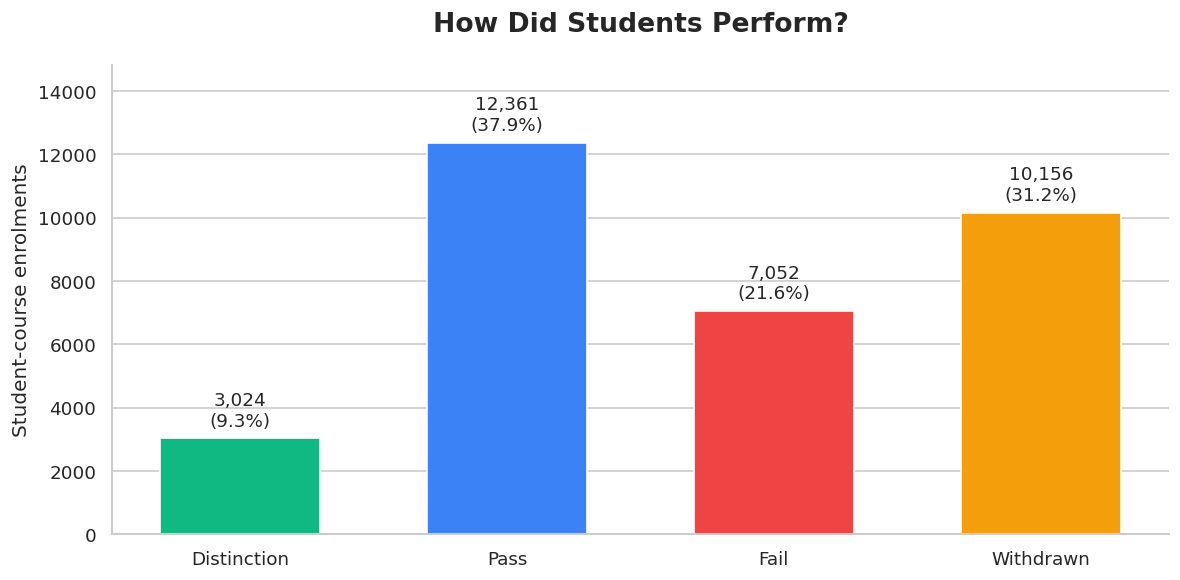

In [26]:
counts = merged["final_result"].value_counts().reindex(order, fill_value=0)

fig, ax = plt.subplots()

bars = ax.bar(
    counts.index,
    counts.values,
    color=[colors[result] for result in order],
    width=0.6
)

labels = [
    f"{count:,}\n({count / len(merged):.1%})"
    for count in counts
]

ax.bar_label(bars, labels=labels, padding=5, fontsize=11)

ax.set_title("How Did Students Perform?", pad=20)
ax.set_xlabel("")
ax.set_ylabel("Student-course enrolments")
ax.set_ylim(0, counts.max() * 1.2)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig("/kaggle/working/final_result_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

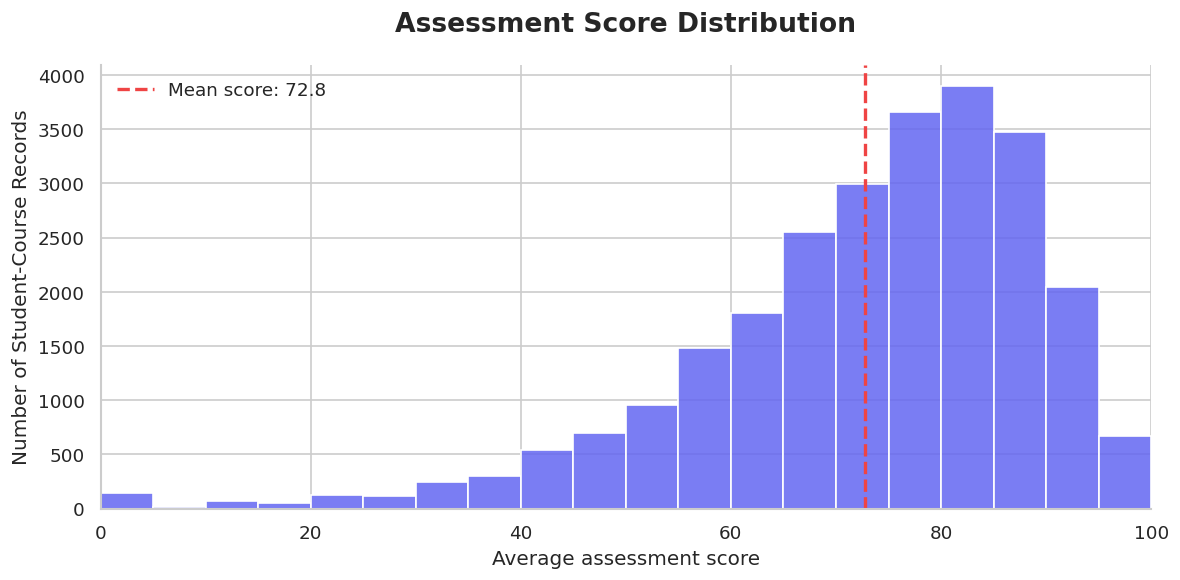

In [27]:
scores = merged["average_score"].dropna()
mean_score = scores.mean()

fig, ax = plt.subplots()

sns.histplot(
    scores,
    bins=20,
    binrange=(0, 100),
    color="#6366F1",
    edgecolor="white",
    alpha=0.85,
    ax=ax
)

ax.axvline(
    mean_score,
    color="#EF4444",
    linestyle="--",
    linewidth=2,
    label=f"Mean score: {mean_score:.1f}"
)

ax.set_title("Assessment Score Distribution", pad=20)
ax.set_xlabel("Average assessment score")
ax.set_ylabel("Number of Student-Course Records")
ax.set_xlim(0, 100)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("/kaggle/working/assessment_score_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

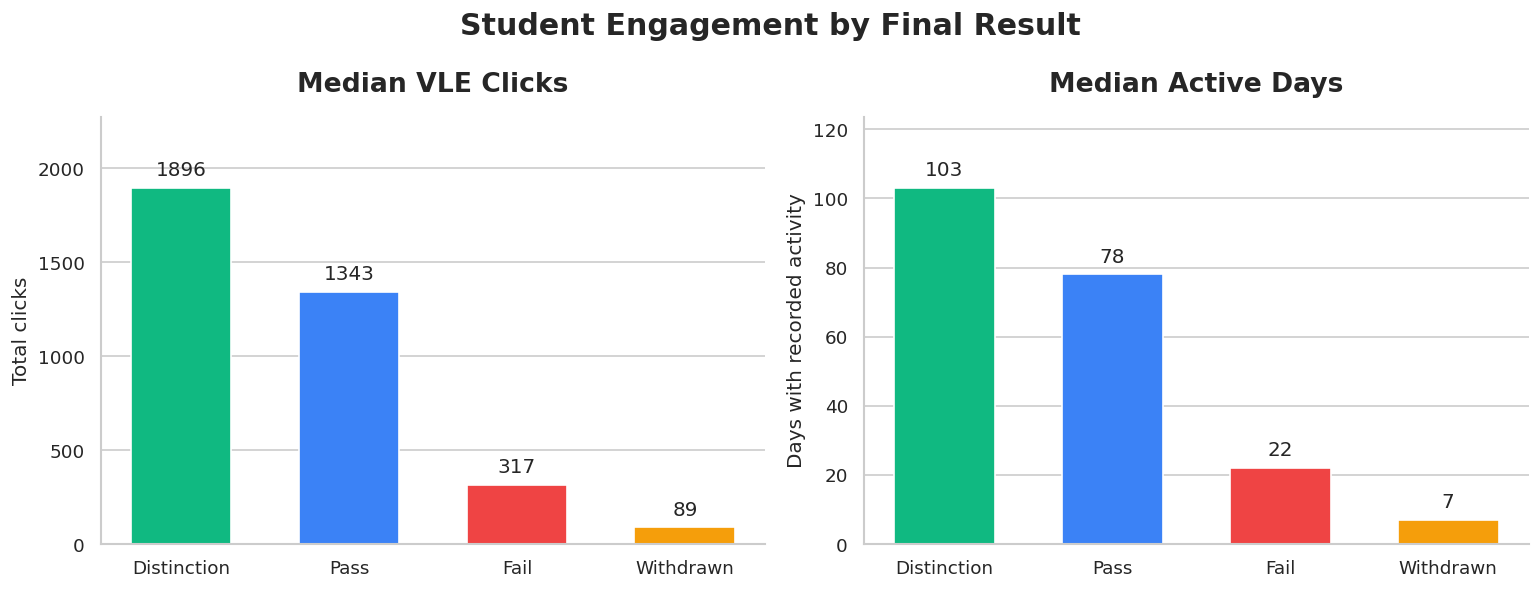

In [28]:
engagement_summary = (
    merged.groupby("final_result")[["total_clicks", "active_days"]]
    .median()
    .reindex(order)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column, title, ylabel in zip(
    axes,
    ["total_clicks", "active_days"],
    ["Median VLE Clicks", "Median Active Days"],
    ["Total clicks", "Days with recorded activity"]
):
    bars = ax.bar(
        order,
        engagement_summary[column],
        color=[colors[result] for result in order],
        width=0.6
    )

    ax.bar_label(bars, fmt="%.0f", padding=5)
    ax.set_title(title, pad=15)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, engagement_summary[column].max() * 1.2)
    ax.grid(axis="x", visible=False)

fig.suptitle("Student Engagement by Final Result", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/engagement_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

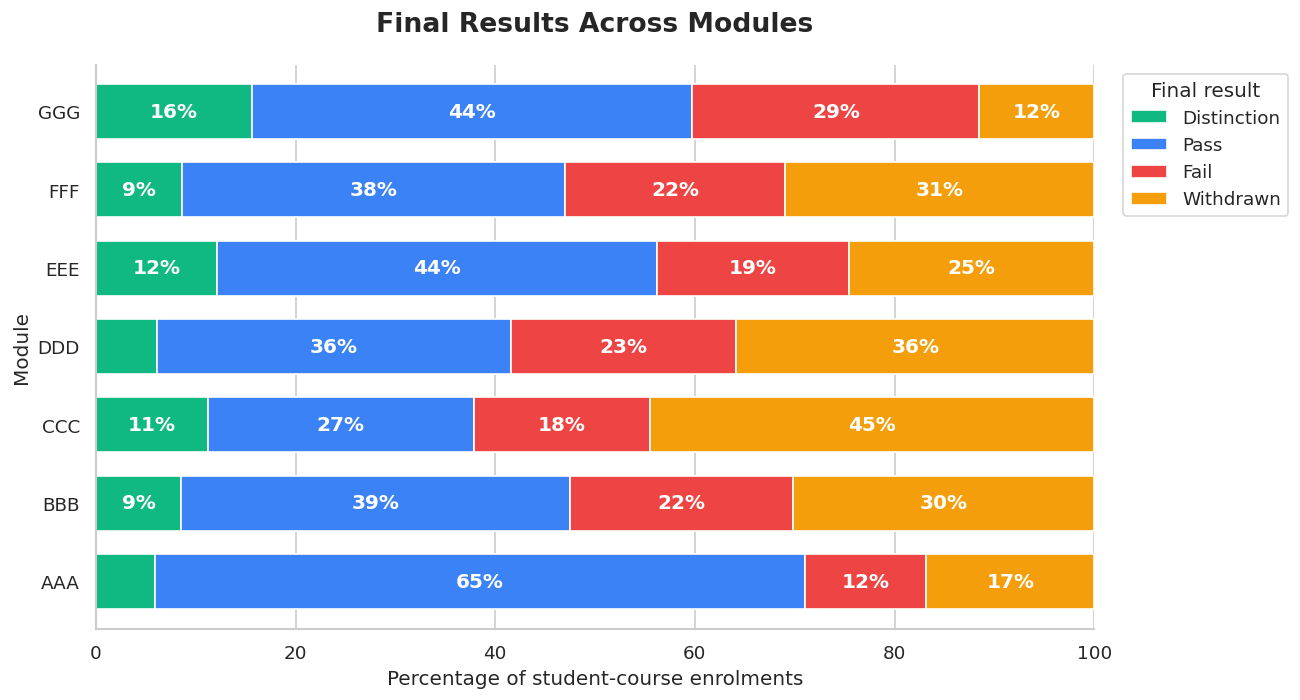

In [29]:
module_results = pd.crosstab(
    merged["code_module"],
    merged["final_result"],
    normalize="index"
).mul(100).reindex(columns=order, fill_value=0)

ax = module_results.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=[colors[result] for result in order],
    width=0.7
)

for container in ax.containers:
    labels = [
        f"{value:.0f}%" if value >= 7 else ""
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, label_type="center",
                 color="white", fontweight="bold")

ax.set_title("Final Results Across Modules", pad=20)
ax.set_xlabel("Percentage of student-course enrolments")
ax.set_ylabel("Module")
ax.set_xlim(0, 100)
ax.legend(title="Final result", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig("/kaggle/working/module_performance.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
merged.isna().sum()

In [31]:
print(merged["average_score"].head(10))

0    82.0
1    66.4
2     NaN
3    76.0
4    54.4
5    68.0
6    68.0
7    72.4
8    71.4
9    78.0
Name: average_score, dtype: float64


| Column | Missing | Meaning and treatment |
|---|---:|---|
| `date_registration` | 45 | Registration date is unavailable. Keep missing. |
| `date_unregistration` | 22,521 | No unregistration date is recorded. Keep missing; zero would mean unregistration on day 0. |
| `clicks_per_active_day` | 3,365 | No recorded active days, so clicks per active day cannot be calculated. Keep missing. |
| `average_score` | 6,773 | No available assessment scores for these enrolments. Keep missing; zero would incorrectly represent a score of 0. |

### Remaining Missing Values

Missing values are retained where information is unavailable or a metric
cannot be calculated. Missing dates are not replaced with artificial
values. Enrolments without recorded activity have no clicks-per-active-day
value, while enrolments without available scores have no average score.
Count columns use zero to indicate no recorded activity or assessments.

## 8. Engagement and Assignment Submission Patterns Across Modules

The dataset does not contain department information or classroom
attendance records. Therefore, comparisons use course modules.

VLE active days describe online engagement rather than attendance.
Assignment submission rates measure the proportion of offered
non-exam assessments with a recorded, non-banked student submission.

**Compare active days across modules**

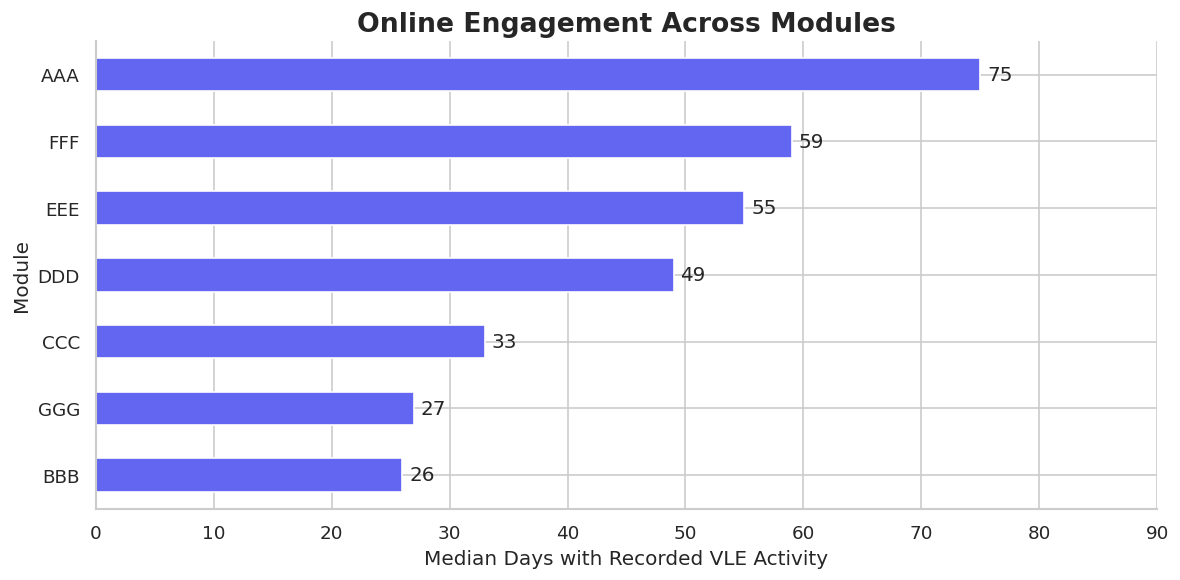

In [32]:
# Calculate median active days for each module
module_activity = (
    merged.groupby("code_module")["active_days"]
    .median()
    .sort_values()
)

ax = module_activity.plot(
    kind="barh",
    color="#6366F1",
    figsize=(10, 5)
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)

plt.title("Online Engagement Across Modules")
plt.xlabel("Median Days with Recorded VLE Activity")
plt.ylabel("Module")
plt.xlim(0, module_activity.max() * 1.2)
plt.tight_layout()
plt.show()

**Calculate assignment submission rates**
Count TMA and CMA assessments, excluding exams. Exclude banked records because they represent credit carried over from an earlier presentation.

In [ ]:
assignments = assessments[assessments["assessment_type"].isin(["TMA", "CMA"])]
assignment_totals = (
    assignments.groupby(["code_module", "code_presentation"])["id_assessment"]
    .nunique().reset_index(name="assignments_offered")
)
assignment_records = student_assessment.merge(
    assignments[["id_assessment", "code_module", "code_presentation"]],
    on="id_assessment", how="inner", validate="many_to_one"
)
assignment_records = assignment_records[assignment_records["is_banked"] == 0]
assignment_counts = (
    assignment_records.groupby(keys)["id_assessment"]
    .nunique().reset_index(name="assignments_submitted")
)
completion = merged[keys + ["final_result"]].copy()
completion = completion.merge(assignment_totals, on=["code_module", "code_presentation"], how="left", validate="many_to_one")
completion = completion.merge(assignment_counts, on=keys, how="left", validate="one_to_one")
completion["assignments_submitted"] = completion["assignments_submitted"].fillna(0).astype(int)
completion["submission_rate"] = (completion["assignments_submitted"] / completion["assignments_offered"] * 100).round(2)

# Aggregate submission patterns only.
display(completion.groupby(["code_module", "code_presentation"])[["assignments_offered", "assignments_submitted", "submission_rate"]].mean().round(2).reset_index())


Plot assignment submission patterns across modules

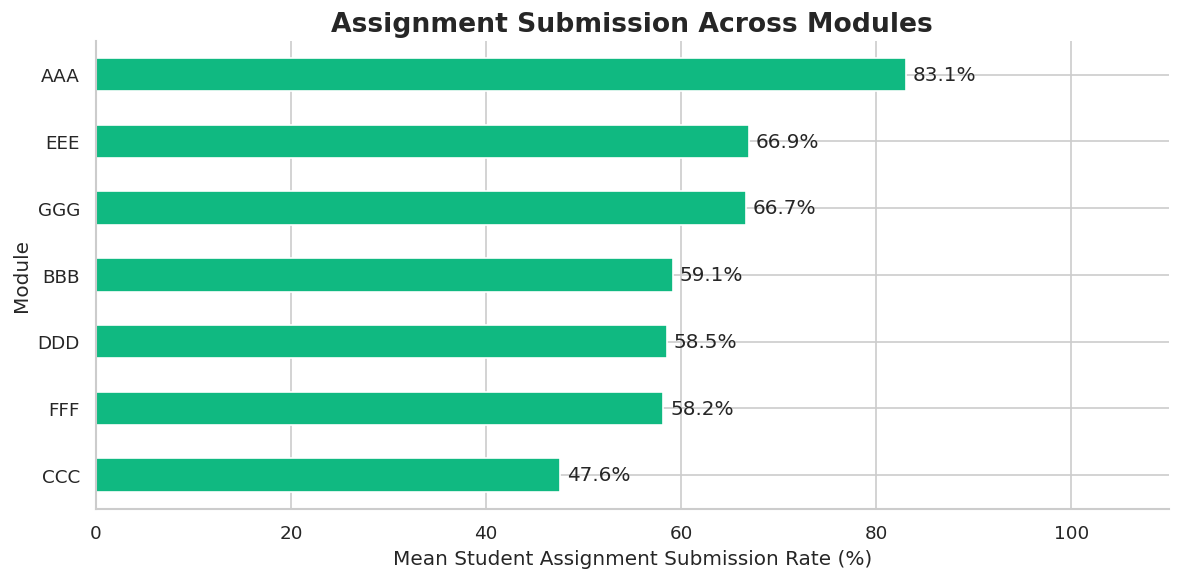

In [34]:
module_completion = (
    completion.groupby("code_module")["submission_rate"]
    .mean()
    .sort_values()
)

ax = module_completion.plot(
    kind="barh",
    color="#10B981",
    figsize=(10, 5)
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)

plt.title("Assignment Submission Across Modules")
plt.xlabel("Mean Student Assignment Submission Rate (%)")
plt.ylabel("Module")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

## Assessment Scores and Submission Timing

Explore individual assessment scores by assessment type, module,
and final outcome. Exclude banked records, which represent credit
carried over from earlier study.

Submission lateness is calculated as submission day minus the
scheduled assessment day.

In [35]:
# Exclude carried-over assessment records
assessment_eda = assessment_details[
    assessment_details["is_banked"] == 0
].copy()

# Add each student's final outcome
assessment_eda = assessment_eda.merge(
    merged[keys + ["final_result"]],
    on=keys,
    how="inner",
    validate="many_to_one"
)

# Positive = late; zero = on time; negative = early
assessment_eda["lateness_days"] = (
    assessment_eda["date_submitted"] - assessment_eda["date"]
)

# Keep available scores for score charts
scored = assessment_eda.dropna(subset=["score"])

**Score distributions by assessment type, module, and outcome**

Boxplots show the median, spread, and differences between groups. Each observation represents an assessment record, so students with more assessments contribute more observations.

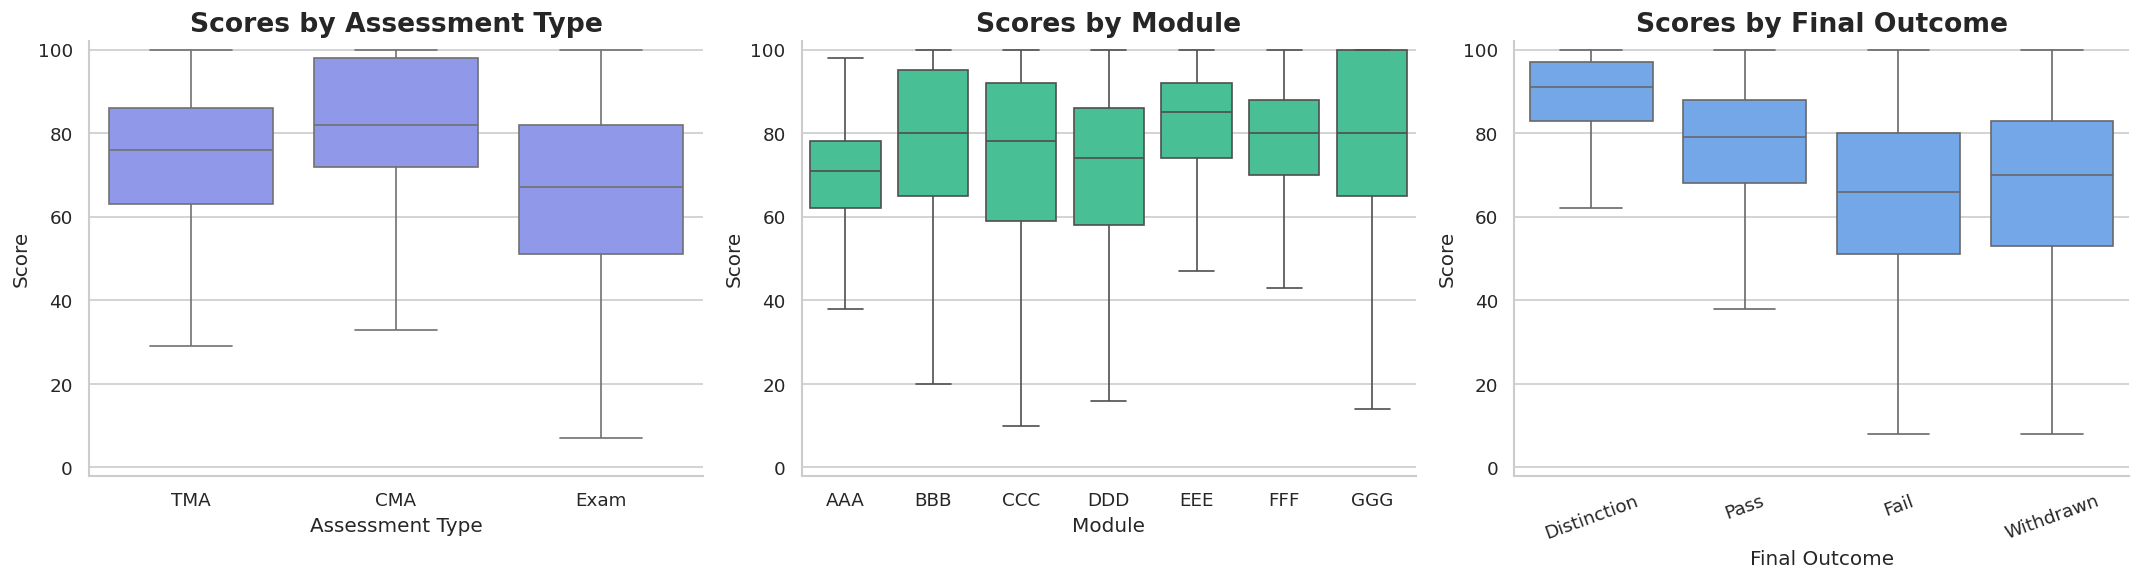

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scores by assessment type
sns.boxplot(
    data=scored,
    x="assessment_type",
    y="score",
    order=["TMA", "CMA", "Exam"],
    color="#818CF8",
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title("Scores by Assessment Type")
axes[0].set_xlabel("Assessment Type")
axes[0].set_ylabel("Score")

# Scores by module
sns.boxplot(
    data=scored,
    x="code_module",
    y="score",
    color="#34D399",
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title("Scores by Module")
axes[1].set_xlabel("Module")
axes[1].set_ylabel("Score")

# Scores by final outcome
sns.boxplot(
    data=scored,
    x="final_result",
    y="score",
    order=order,
    color="#60A5FA",
    showfliers=False,
    ax=axes[2]
)

axes[2].set_title("Scores by Final Outcome")
axes[2].set_xlabel("Final Outcome")
axes[2].set_ylabel("Score")
axes[2].tick_params(axis="x", rotation=20)

for ax in axes:
    ax.set_ylim(-2, 102)

plt.tight_layout()
plt.savefig("/kaggle/working/assessment_score_comparisons.png",
            dpi=300, bbox_inches="tight")
plt.show()

Submission lateness distribution

Use TMA and CMA records with known scheduled dates. Missing scores do not prevent a recorded submission from being included.

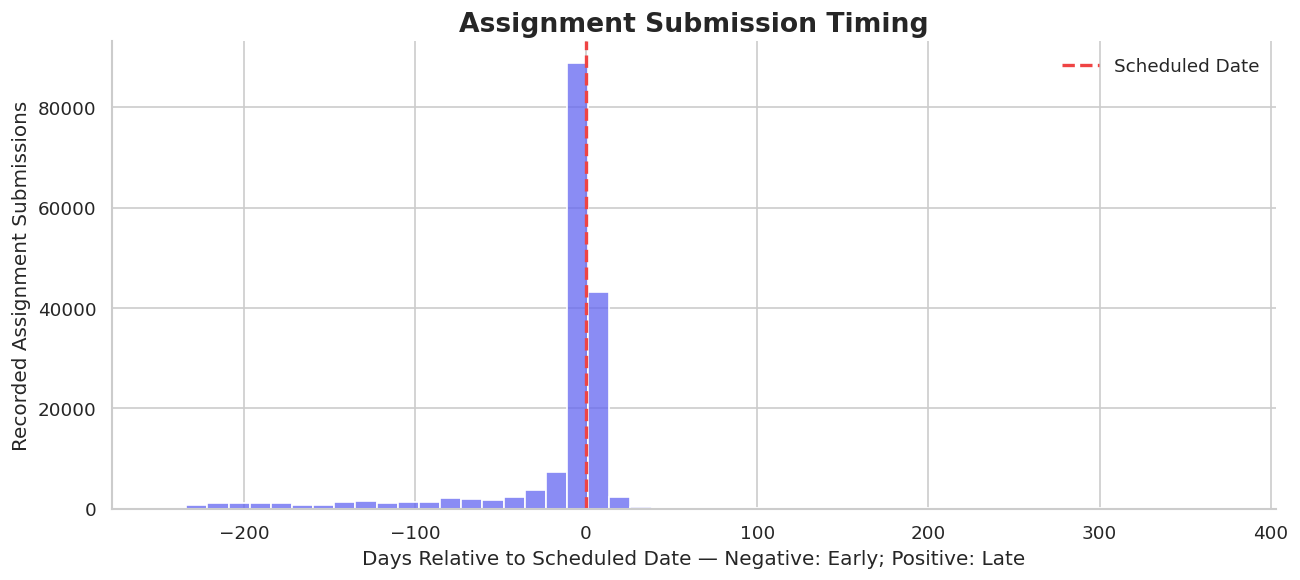

,Submissions,Percentage
Early,88264,52.8
On time,29469,17.6
Late,49311,29.5


In [37]:
# Select assignments with known submission and scheduled dates
timing = assessment_eda[
    assessment_eda["assessment_type"].isin(["TMA", "CMA"])
].dropna(subset=["lateness_days"])

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    data=timing,
    x="lateness_days",
    bins=50,
    color="#6366F1",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    0,
    color="#EF4444",
    linestyle="--",
    linewidth=2,
    label="Scheduled Date"
)

ax.set_title("Assignment Submission Timing")
ax.set_xlabel("Days Relative to Scheduled Date — Negative: Early; Positive: Late")
ax.set_ylabel("Recorded Assignment Submissions")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("/kaggle/working/submission_lateness.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Summarise early, on-time, and late submissions
timing_summary = pd.Series({
    "Early": (timing["lateness_days"] < 0).sum(),
    "On time": (timing["lateness_days"] == 0).sum(),
    "Late": (timing["lateness_days"] > 0).sum()
}).to_frame("Submissions")

timing_summary["Percentage"] = (
    timing_summary["Submissions"] / len(timing) * 100
).round(1)

display(timing_summary)

## Student Characteristics and Final Outcomes

Compare outcome percentages across deprivation bands, age groups,
education levels, and previous attempts.

Each observation represents a student-course enrolment.
These comparisons describe associations and do not establish causes.

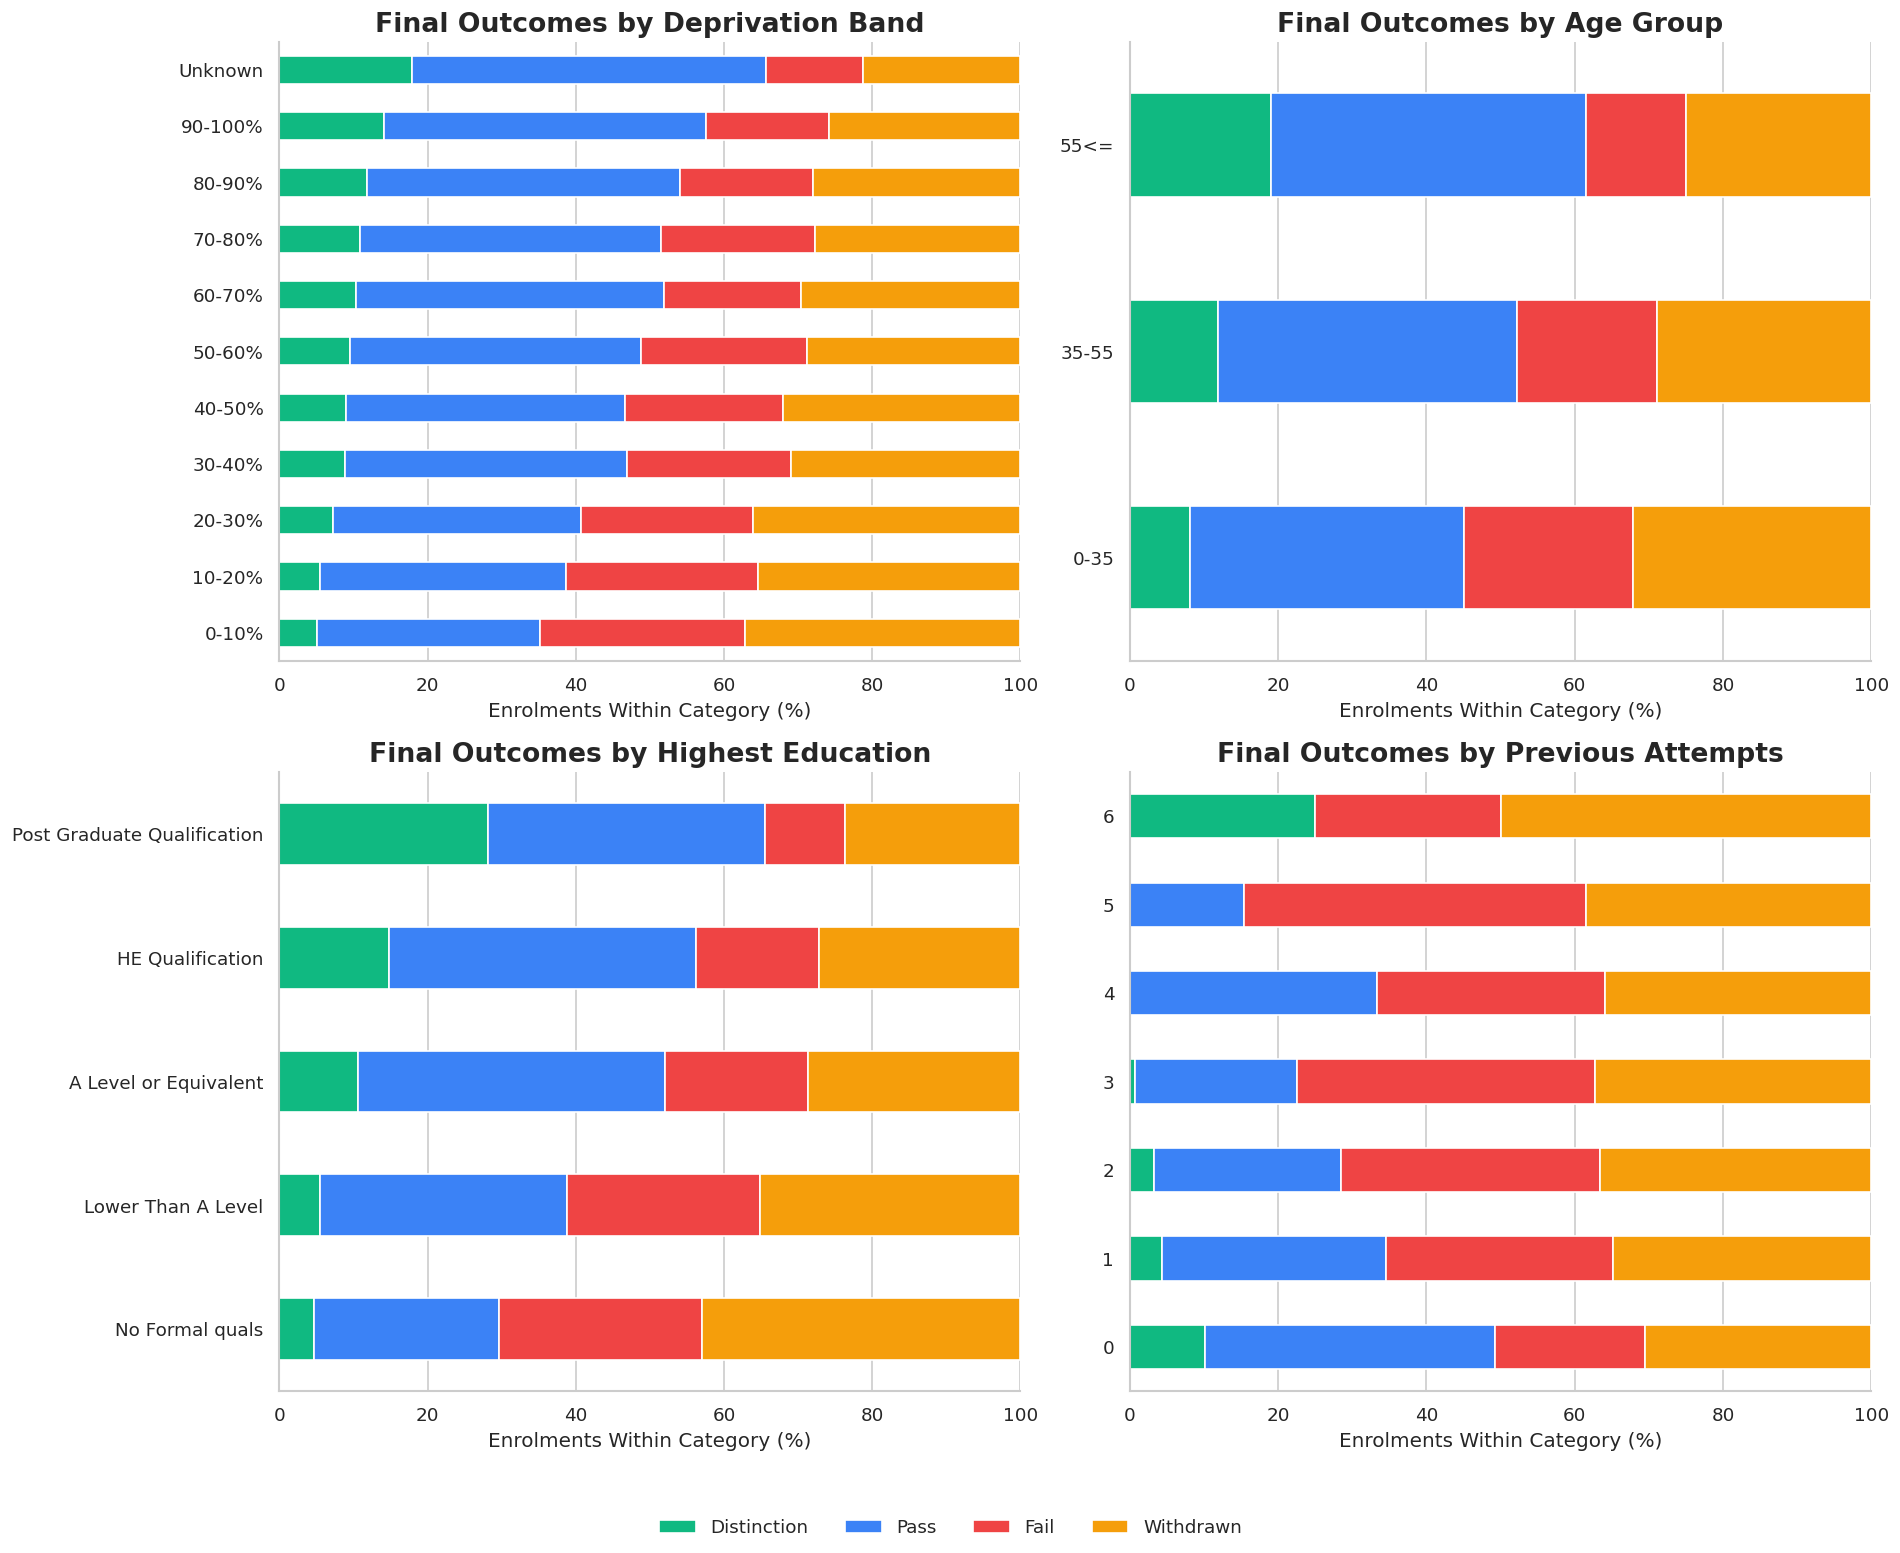

In [38]:
# Arrange demographic categories in a meaningful order
imd_order = [
    "0-10%", "10-20%", "20-30%", "30-40%", "40-50%",
    "50-60%", "60-70%", "70-80%", "80-90%", "90-100%",
    "Unknown"
]

age_order = ["0-35", "35-55", "55<="]

education_order = [
    "No Formal quals",
    "Lower Than A Level",
    "A Level or Equivalent",
    "HE Qualification",
    "Post Graduate Qualification"
]

demographics = [
    ("imd_band", "Deprivation Band", imd_order),
    ("age_band", "Age Group", age_order),
    ("highest_education", "Highest Education", education_order),
    (
        "num_of_prev_attempts",
        "Previous Attempts",
        sorted(merged["num_of_prev_attempts"].unique())
    )
]

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

for ax, (column, title, category_order) in zip(
    axes.flat, demographics
):
    # Calculate outcome percentages within each category
    percentages = pd.crosstab(
        merged[column],
        merged["final_result"],
        normalize="index"
    ).mul(100)

    percentages = percentages.reindex(
        index=category_order,
        columns=order,
        fill_value=0
    )

    percentages.plot(
        kind="barh",
        stacked=True,
        color=[colors[result] for result in order],
        ax=ax,
        legend=False
    )

    ax.set_title(f"Final Outcomes by {title}")
    ax.set_xlabel("Enrolments Within Category (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)

# Add one shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("/kaggle/working/demographics_and_outcomes.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [39]:
for column, title, category_order in demographics:
    print(f"\n{title}: Enrolment Counts")

    display(
        merged[column]
        .value_counts()
        .reindex(category_order, fill_value=0)
        .to_frame("Enrolments")
    )


Deprivation Band: Enrolment Counts


,Enrolments
imd_band,
0-10%,3311
10-20%,3516
20-30%,3654
30-40%,3539
40-50%,3256
50-60%,3124
60-70%,2905
70-80%,2879
80-90%,2762



Age Group: Enrolment Counts


,Enrolments
age_band,
0-35,22944
35-55,9433
55<=,216



Highest Education: Enrolment Counts


,Enrolments
highest_education,
No Formal quals,347
Lower Than A Level,13158
A Level or Equivalent,14045
HE Qualification,4730
Post Graduate Qualification,313



Previous Attempts: Enrolment Counts


,Enrolments
num_of_prev_attempts,
0,28421
1,3299
2,675
3,142
4,39
5,13
6,4


In [40]:
from IPython.display import Markdown, display

# Final result distribution
result_counts = merged["final_result"].value_counts()
largest_result = result_counts.idxmax()
largest_percentage = result_counts.max() / len(merged) * 100

# Assessment scores
available_scores = merged["average_score"].dropna()

# Engagement by final result
engagement_medians = (
    merged.groupby("final_result")[["total_clicks", "active_days"]]
    .median()
)

highest_clicks = engagement_medians["total_clicks"].idxmax()
highest_days = engagement_medians["active_days"].idxmax()

# Final results across modules
module_results = pd.crosstab(
    merged["code_module"],
    merged["final_result"],
    normalize="index"
).mul(100)

# Combine Pass and Distinction as successful outcomes
module_success = module_results[["Pass", "Distinction"]].sum(axis=1)
highest_success = module_success.idxmax()

findings = f"""
## Key Findings

### 1. Final Result Distribution
**{largest_result}** is the largest outcome group, accounting for
**{result_counts.max():,} enrolments ({largest_percentage:.1f}%)**.

### 2. Assessment Score Distribution
Among enrolments with available scores, the mean student-level average
score is **{available_scores.mean():.2f}/100**, and the median is
**{available_scores.median():.2f}/100**.
**{merged["average_score"].isna().sum():,} enrolments** have no available
average score and are excluded from this distribution.

### 3. Engagement by Final Result
The **{highest_clicks}** group has the highest median total clicks
(**{engagement_medians.loc[highest_clicks, "total_clicks"]:,.0f}**).
The **{highest_days}** group has the highest median active days
(**{engagement_medians.loc[highest_days, "active_days"]:.0f} days**).

These are associations between recorded engagement and outcomes;
they do not establish causation.

### 4. Final Results Across Modules
Module **{highest_success}** has the highest combined percentage of
Pass and Distinction outcomes (**{module_success.max():.1f}%**).
These comparisons pool presentations within each module.
"""

display(Markdown(findings))


## Key Findings

### 1. Final Result Distribution
**Pass** is the largest outcome group, accounting for
**12,361 enrolments (37.9%)**.

### 2. Assessment Score Distribution
Among enrolments with available scores, the mean student-level average
score is **72.77/100**, and the median is
**76.00/100**.
**6,773 enrolments** have no available
average score and are excluded from this distribution.

### 3. Engagement by Final Result
The **Distinction** group has the highest median total clicks
(**1,896**).
The **Distinction** group has the highest median active days
(**103 days**).

These are associations between recorded engagement and outcomes;
they do not establish causation.

### 4. Final Results Across Modules
Module **AAA** has the highest combined percentage of
Pass and Distinction outcomes (**71.0%**).
These comparisons pool presentations within each module.


## Define the Prediction Target and Features

The target identifies an unsuccessful final outcome:
- 1: Fail or Withdrawn
- 0: Pass or Distinction

The initial model uses student and course information available at
enrolment. Full-course engagement, assessment summaries, and
unregistration dates are excluded because they contain information
from after the prediction point.

In [41]:
# Work on a separate copy for modelling
model_data = merged.copy()

# Define the target from the final outcome
model_data["risk"] = model_data["final_result"].map({
    "Fail": 1,
    "Withdrawn": 1,
    "Pass": 0,
    "Distinction": 0
})

# Check that every outcome was mapped
assert model_data["risk"].notna().all()

model_data["risk"] = model_data["risk"].astype(int)

# Select baseline features available at enrolment
feature_columns = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability",
    "module_presentation_length"
]

# Inputs and target
X = model_data[feature_columns].copy()
y = model_data["risk"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (32593, 11)
Target shape: (32593,)


,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,module_presentation_length
0,AAA,2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,268
1,AAA,2013J,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,268
2,AAA,2013J,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,268
3,AAA,2013J,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,268
4,AAA,2013J,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,268


In [42]:
target_summary = (
    y.value_counts()
    .reindex([0, 1], fill_value=0)
    .to_frame("Enrolments")
)

target_summary["Percentage"] = (
    target_summary["Enrolments"] / len(y) * 100
).round(2)

target_summary.index = ["Successful (0)", "At risk (1)"]

display(target_summary)

,Enrolments,Percentage
Successful (0),15385,47.2
At risk (1),17208,52.8


#  Retention Funnel Analysis

Define the key columns used to uniquely identify each student within a specific module and presentation. These columns are used to link datasets and maintain accurate student records during data merging and analysis.

In [43]:
KEY = ["code_module", "code_presentation", "id_student"]

### Create the Base Retention Funnel Dataset

Create the initial funnel dataset using student registration details, including registration and unregistration dates. Merge the final academic results from the student information table using the key columns to prepare the data for retention analysis.

In [ ]:
funnel = registration[KEY + ["date_registration", "date_unregistration"]].drop_duplicates()
funnel = funnel.merge(student_info[KEY + ["final_result"]], on=KEY, how="left")
print("Registered enrolment records:", len(funnel))
print("Module-presentation combinations:", funnel[["code_module", "code_presentation"]].drop_duplicates().shape[0])


### Identify Students Active on Day 0

Identify students who recorded at least one click on the Virtual Learning Environment (VLE) on Day 0. Create the `Active_Day_0` indicator, assigning `1` to active students and `0` to students with no recorded activity on that day. Merge this indicator into the retention funnel dataset.

In [45]:
day0 = student_vle[
    (student_vle["date"] == 0) &
    (student_vle["sum_click"] > 0)
][KEY].drop_duplicates()

day0["Active_Day_0"] = 1

funnel = funnel.merge(day0, on=KEY, how="left")

funnel["Active_Day_0"] = (
    funnel["Active_Day_0"].fillna(0).astype(int)
)

print(funnel["Active_Day_0"].value_counts())

Active_Day_0
0    23142
1     9451
Name: count, dtype: int64


### Identify the First Scheduled Assessment

Identify the earliest scheduled assessment date for each module and presentation. Exclude assessments with missing dates, then select the assessment ID associated with the earliest available date. This information will be used to identify students who submitted the first scheduled assessment.

In [46]:
valid_assessments = assessments.dropna(subset=["date"])

first_assessment = valid_assessments.loc[
    valid_assessments.groupby(
        ["code_module", "code_presentation"]
    )["date"].idxmin(),
    ["code_module", "code_presentation", "id_assessment"]
]

print(first_assessment.head())

   code_module code_presentation  id_assessment
0          AAA             2013J           1752
6          AAA             2014J           1758
17         BBB             2013B          14984
29         BBB             2013J          14996
41         BBB             2014B          15008


### Identify First Assessment Submissions

Identify students who submitted the first scheduled assessment in each module presentation. Create an indicator to mark students who submitted the assessment (`1`) and those without a recorded submission (`0`).

In [47]:
submissions = student_assessment.merge(
    assessments[
        ["id_assessment", "code_module", "code_presentation"]
    ],
    on="id_assessment",
    how="inner"
)

submissions = submissions.merge(
    first_assessment,
    on=["code_module", "code_presentation", "id_assessment"],
    how="inner"
)

first_submissions = submissions[
    submissions["date_submitted"].notna()
][["code_module", "code_presentation", "id_student"]].drop_duplicates()

first_submissions["Submitted_First_Assessment"] = 1

funnel = funnel.merge(
    first_submissions,
    on=KEY,
    how="left"
)

funnel["Submitted_First_Assessment"] = (
    funnel["Submitted_First_Assessment"].fillna(0).astype(int)
)

print(funnel["Submitted_First_Assessment"].value_counts())

Submitted_First_Assessment
1    25385
0     7208
Name: count, dtype: int64


### Identify Mid-Module Retention

Calculate the midpoint of each module and check whether students were still registered at that time. Mark students who meet this condition as `1` and others as `0`.

In [48]:
funnel = funnel.merge(
    courses,
    on=["code_module", "code_presentation"],
    how="left"
)

funnel["midpoint"] = (
    funnel["module_presentation_length"] // 2
)

funnel["Still_Registered_Mid_Module"] = (
    (funnel["date_registration"] <= funnel["midpoint"]) &
    (
        funnel["date_unregistration"].isna() |
        (funnel["date_unregistration"] > funnel["midpoint"])
    )
).astype(int)

print(funnel["Still_Registered_Mid_Module"].value_counts())

Still_Registered_Mid_Module
1    24592
0     8001
Name: count, dtype: int64


### Identify Module Completion and Passing

Use students' final results to identify those who completed the module and those who passed. Students with `Pass`, `Distinction`, or `Fail` are marked as completed, while students with `Pass` or `Distinction` are marked as passed.

In [49]:
funnel["Completed_Module"] = (
    funnel["final_result"].isin(["Pass", "Distinction", "Fail"])
).astype(int)

funnel["Passed"] = (
    funnel["final_result"].isin(["Pass", "Distinction"])
).astype(int)

print(funnel["Completed_Module"].value_counts())
print(funnel["Passed"].value_counts())

Completed_Module
1    22437
0    10156
Name: count, dtype: int64
Passed
0    17208
1    15385
Name: count, dtype: int64


In [50]:
funnel["Funnel_Active_Day_0"] = (
    funnel["Active_Day_0"] == 1
).astype(int)

funnel["Funnel_First_Assessment"] = (
    (funnel["Funnel_Active_Day_0"] == 1) &
    (funnel["Submitted_First_Assessment"] == 1)
).astype(int)

funnel["Funnel_Mid_Module"] = (
    (funnel["Funnel_First_Assessment"] == 1) &
    (funnel["Still_Registered_Mid_Module"] == 1)
).astype(int)

funnel["Funnel_Completed"] = (
    (funnel["Funnel_Mid_Module"] == 1) &
    (funnel["Completed_Module"] == 1)
).astype(int)

funnel["Funnel_Passed"] = (
    (funnel["Funnel_Completed"] == 1) &
    (funnel["Passed"] == 1)
).astype(int)

### Aggregate Retention Funnel Counts

Group students by module and presentation to calculate the total registered students and the number of students in each retention and academic outcome stage. The resulting table summarizes student progress for each module presentation.

In [51]:

funnel_counts = funnel.groupby(
    ["code_module", "code_presentation"]
).agg(
    Registered=("id_student", "nunique"),
    Active_Day_0=("Funnel_Active_Day_0", "sum"),
    Submitted_First_Assessment=("Funnel_First_Assessment", "sum"),
    Still_Registered_Mid_Module=("Funnel_Mid_Module", "sum"),
    Completed_Module=("Funnel_Completed", "sum"),
    Passed=("Funnel_Passed", "sum")
).reset_index()

display(funnel_counts.head(10))


,code_module,code_presentation,Registered,Active_Day_0,Submitted_First_Assessment,Still_Registered_Mid_Module,Completed_Module,Passed
0,AAA,2013J,383,143,139,132,125,114
1,AAA,2014J,365,130,122,113,103,95
2,BBB,2013B,1767,380,356,340,311,239
3,BBB,2013J,2237,414,391,365,350,265
4,BBB,2014B,1613,311,303,276,262,196
5,BBB,2014J,2292,495,469,415,386,310
6,CCC,2014B,1936,521,467,389,334,254
7,CCC,2014J,2498,647,595,487,431,357
8,DDD,2013B,1303,436,405,361,324,235
9,DDD,2013J,1938,634,571,510,457,344


In [52]:
print(funnel_counts.columns.tolist())
display(funnel_counts.head())

['code_module', 'code_presentation', 'Registered', 'Active_Day_0', 'Submitted_First_Assessment', 'Still_Registered_Mid_Module', 'Completed_Module', 'Passed']


,code_module,code_presentation,Registered,Active_Day_0,Submitted_First_Assessment,Still_Registered_Mid_Module,Completed_Module,Passed
0,AAA,2013J,383,143,139,132,125,114
1,AAA,2014J,365,130,122,113,103,95
2,BBB,2013B,1767,380,356,340,311,239
3,BBB,2013J,2237,414,391,365,350,265
4,BBB,2014B,1613,311,303,276,262,196


In [53]:
stage_columns = [
    "Registered",
    "Active_Day_0",
    "Submitted_First_Assessment",
    "Still_Registered_Mid_Module",
    "Completed_Module",
    "Passed"
]

print("Duplicate module-presentation rows:")
print(
    funnel_counts.duplicated(
        ["code_module", "code_presentation"]
    ).sum()
)

print("Funnel is monotonically decreasing:")
print(
    funnel_counts[stage_columns]
    .diff(axis=1)
    .iloc[:, 1:]
    .le(0)
    .all()
    .all()
)

Duplicate module-presentation rows:
0
Funnel is monotonically decreasing:
True


In [54]:
funnel_counts.to_csv(
    "retention_funnel_by_presentation.csv",
    index=False
)

print("Retention funnel CSV saved successfully!")

Retention funnel CSV saved successfully!


In [55]:
funnel_counts[
    (funnel_counts["code_module"] == "AAA") &
    (funnel_counts["code_presentation"] == "2013J")
]

,code_module,code_presentation,Registered,Active_Day_0,Submitted_First_Assessment,Still_Registered_Mid_Module,Completed_Module,Passed
0,AAA,2013J,383,143,139,132,125,114


# Department risk dashboard charts

In [56]:

import pandas as pd
import plotly.express as px

# Define student outcomes
risk_results = ["Fail", "Withdrawn"]

# Aggregate students by module and presentation
risk_summary = (
    merged.groupby(["code_module", "code_presentation"])
    .agg(
        registered_students=("id_student", "nunique"),
        at_risk_students=(
            "final_result",
            lambda s: s.isin(risk_results).sum()
        ),
        dropout_students=(
            "final_result",
            lambda s: s.eq("Withdrawn").sum()
        )
    )
    .reset_index()
)

# Calculate percentages
risk_summary["at_risk_rate"] = (
    risk_summary["at_risk_students"]
    / risk_summary["registered_students"] * 100
)

risk_summary["dropout_rate"] = (
    risk_summary["dropout_students"]
    / risk_summary["registered_students"] * 100
)

display(risk_summary.head(10))


,code_module,code_presentation,registered_students,at_risk_students,dropout_students,at_risk_rate,dropout_rate
0,AAA,2013J,383,105,60,27.415144,15.665796
1,AAA,2014J,365,112,66,30.684932,18.082192
2,BBB,2013B,1767,964,505,54.555744,28.579513
3,BBB,2013J,2237,1165,644,52.078677,28.788556
4,BBB,2014B,1613,886,490,54.928704,30.378177
5,BBB,2014J,2292,1140,749,49.738220,32.678883
6,CCC,2014B,1936,1273,898,65.754132,46.384298
7,CCC,2014J,2498,1483,1077,59.367494,43.114492
8,DDD,2013B,1303,793,432,60.859555,33.154259
9,DDD,2013J,1938,1109,681,57.223942,35.139319


In [57]:

def plot_risk_bar(data, metric, title, y_label):
    """Create a reusable grouped bar chart."""
    fig = px.bar(
        data,
        x="code_module",
        y=metric,
        color="code_presentation",
        barmode="group",
        text_auto=".1f",
        title=title,
        labels={
            "code_module": "Module",
            "code_presentation": "Presentation",
            metric: y_label
        }
    )

    fig.update_layout(
        xaxis_title="Module",
        yaxis_title=y_label,
        legend_title="Presentation",
        template="plotly_white"
    )
    fig.show()


def plot_risk_heatmap(data, metric, title):
    """Create a reusable module-versus-presentation heatmap."""
    heatmap_data = data.pivot(
        index="code_module",
        columns="code_presentation",
        values=metric
    )

    fig = px.imshow(
        heatmap_data,
        text_auto=".1f",
        aspect="auto",
        color_continuous_scale="Reds",
        title=title,
        labels={
            "x": "Presentation",
            "y": "Module",
            "color": "Percentage"
        }
    )

    fig.update_layout(template="plotly_white")
    fig.show()


In [58]:

# 1. At-risk student concentration by count
plot_risk_bar(
    risk_summary,
    "at_risk_students",
    "At-Risk Student Count by Module and Presentation",
    "Number of At-Risk Students"
)

# 2. At-risk rate heatmap
plot_risk_heatmap(
    risk_summary,
    "at_risk_rate",
    "At-Risk Student Rate (%) by Module and Presentation"
)

# 3. Dropout rate bar chart
plot_risk_bar(
    risk_summary,
    "dropout_rate",
    "Dropout Rate by Module and Presentation",
    "Dropout Rate (%)"
)

# 4. Dropout rate heatmap
plot_risk_heatmap(
    risk_summary,
    "dropout_rate",
    "Dropout Rate (%) by Module and Presentation"
)


# At-Risk Indicator Combination Analysis

Compare combinations of low assessment scores, low online activity,
and late submissions recorded by Day 30 with final failure or withdrawal.

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from pathlib import Path

KEY = ["code_module", "code_presentation", "id_student"]

# Analysis settings: choose these before looking at the results
CUTOFF_DAY = 30
LOW_SCORE_THRESHOLD = 40
LOW_ACTIVITY_THRESHOLD = 8

# Save results in a relative folder
RESULTS_DIR = Path("outputs/indicator_combinations")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

Explanation: Flags are exploratory starting thresholds, not proven optimal values. A low score means an average available non-banked TMA/CMA score below 40 by Day 30; low activity means fewer than 8 active VLE days from Day 0 through Day 30; late submission means at least one observed submission by Day 30 after its known deadline.

Step 2: Select the Day 30 active population
The project definition is students still active at Day 30: registered by the cutoff and not unregistered on or before Day 30. The target is final Fail or Withdrawn. Verify the resulting count against the agreed reference population of 27,466.


In [ ]:
analysis = merged[
    KEY + ["date_registration", "date_unregistration", "final_result"]
].copy()

eligible = (
    (analysis["date_registration"].isna() | (analysis["date_registration"] <= CUTOFF_DAY))
    & (analysis["date_unregistration"].isna() | (analysis["date_unregistration"] > CUTOFF_DAY))
)
analysis = analysis.loc[eligible].copy()

analysis["at_risk"] = analysis["final_result"].map({
    "Fail": 1, "Withdrawn": 1, "Pass": 0, "Distinction": 0
})
assert analysis["at_risk"].notna().all()
assert not analysis.duplicated(KEY).any()
analysis["at_risk"] = analysis["at_risk"].astype(int)

print("Day 30 active student-course records:", len(analysis))
print(f"At-risk rate (Fail or Withdrawn): {analysis['at_risk'].mean():.1%}")
print("Project reference population: 27,466 records")
if len(analysis) != 27466:
    print("CHECK REQUIRED: count differs from the project reference; verify missing registration-date handling and source joins before interpreting results.")


Explanation: Each row represents one student taking one module in one presentation. A student can therefore appear more than once.

Step 3: Calculate the three Day 30 metrics
A. Online activity
Count days with positive clicks between Day 0 and Day 30.

In [61]:
early_activity = student_vle.loc[
    student_vle["date"].between(0, CUTOFF_DAY)
    & student_vle["sum_click"].gt(0)
].copy()

activity_summary = (
    early_activity.groupby(KEY)["date"]
    .nunique()
    .reset_index(name="active_days_day30")
)

analysis = analysis.merge(
    activity_summary,
    on=KEY,
    how="left",
    validate="one_to_one"
)

# No recorded positive clicks means zero recorded active days
analysis["active_days_day30"] = (
    analysis["active_days_day30"].fillna(0).astype(int)
)

Assessment scores and late submissions
Use non-banked TMA/CMA submissions recorded by Day 30. Banked assessments represent credit carried over from earlier study.

In [ ]:
early_assessments = assessment_details.loc[
    assessment_details["assessment_type"].isin(["TMA", "CMA"])
    & assessment_details["is_banked"].eq(0)
    & assessment_details["date_submitted"].between(0, CUTOFF_DAY)
].copy()

score_summary = early_assessments.groupby(KEY)["score"].mean().reset_index(name="average_score_day30")
timed_assessments = early_assessments.dropna(subset=["date", "date_submitted"]).copy()
timed_assessments["is_late"] = timed_assessments["date_submitted"] > timed_assessments["date"]
late_summary = timed_assessments.groupby(KEY).agg(
    timed_submissions=("is_late", "size"), late_submissions=("is_late", "sum")
).reset_index()
analysis = analysis.merge(score_summary, on=KEY, how="left", validate="one_to_one")
analysis = analysis.merge(late_summary, on=KEY, how="left", validate="one_to_one")

# Aggregate coverage only; do not display student-level rows or identifiers.
print("Records with a Day 30 score:", int(analysis["average_score_day30"].notna().sum()))
print("Records with at least one timed Day 30 submission:", int(analysis["timed_submissions"].notna().sum()))


A submission is late when its submission day is later than its scheduled deadline. Only non-banked TMA/CMA submissions made on Days 0–30 are used. Missing submissions are not automatically late; records without a known deadline remain unknown for the late-submission flag. Note that submission by Day 30 does not guarantee the score was marked by Day 30.


In [63]:
# Nullable integers allow unknown values to remain missing
analysis["low_score"] = (
    analysis["average_score_day30"]
    .lt(LOW_SCORE_THRESHOLD)
    .astype("Int64")
)

analysis.loc[
    analysis["average_score_day30"].isna(),
    "low_score"
] = pd.NA

analysis["low_activity"] = (
    analysis["active_days_day30"]
    .lt(LOW_ACTIVITY_THRESHOLD)
    .astype("Int64")
)

analysis["late_submission"] = (
    analysis["late_submissions"]
    .gt(0)
    .astype("Int64")
)

analysis.loc[
    analysis["timed_submissions"].isna(),
    "late_submission"
] = pd.NA

FLAGS = ["low_score", "low_activity", "late_submission"]

display(analysis[FLAGS].head(10))

,low_score,low_activity,late_submission
0,0,0,0
1,0,0,1
2,0,0,0
3,0,0,1
4,0,0,0
5,0,0,1
6,0,0,0
7,0,0,0
8,0,0,0
9,0,0,0


In [64]:
complete = analysis[FLAGS].notna().all(axis=1)

segments_data = analysis.loc[complete].copy()

coverage = pd.DataFrame([
    {
        "population": "All eligible",
        "size": len(analysis),
        "at_risk_rate": analysis["at_risk"].mean()
    },
    {
        "population": "Included: all flags known",
        "size": complete.sum(),
        "at_risk_rate": analysis.loc[complete, "at_risk"].mean()
    },
    {
        "population": "Excluded: unknown flag",
        "size": (~complete).sum(),
        "at_risk_rate": analysis.loc[~complete, "at_risk"].mean()
    }
])

display(coverage)

if segments_data.empty:
    raise ValueError(
        "No records have all three flags available. "
        "Check assessment coverage before continuing."
    )

,population,size,at_risk_rate
0,All eligible,27443,0.439639
1,Included: all flags known,20358,0.391443
2,Excluded: unknown flag,7085,0.578123


Records with one or more unknown indicators are excluded from the eight-combination comparison because the combination cannot be assigned reliably. Coverage and outcome rates are reported for eligible, included, and excluded records so this selection is visible. If the Day 30 population count does not match 27,466, resolve the population discrepancy before interpreting the combination results.


In [65]:
SEGMENT_NAMES = {
    (0, 0, 0): "No flags",
    (1, 0, 0): "Low score only",
    (0, 1, 0): "Low activity only",
    (0, 0, 1): "Late submission only",
    (1, 1, 0): "Low score + low activity",
    (1, 0, 1): "Low score + late submission",
    (0, 1, 1): "Low activity + late submission",
    (1, 1, 1): "All three flags"
}

segments_data["segment"] = [
    SEGMENT_NAMES[tuple(int(value) for value in row)]
    for row in segments_data[FLAGS].itertuples(
        index=False, name=None
    )
]

# Keep all eight combinations, including empty ones
segment_order = list(SEGMENT_NAMES.values())

segment_table = (
    segments_data.groupby("segment")
    .agg(
        segment_size=("at_risk", "size"),
        at_risk_count=("at_risk", "sum")
    )
    .reindex(segment_order, fill_value=0)
)

segment_table["at_risk_rate"] = (
    segment_table["at_risk_count"]
    / segment_table["segment_size"].replace(0, np.nan)
)

# Use the same population for the baseline and segment rates
baseline_rate = segments_data["at_risk"].mean()

segment_table["lift"] = (
    segment_table["at_risk_rate"] / baseline_rate
    if baseline_rate > 0
    else np.nan
)

print(f"Included-population baseline rate: {baseline_rate:.1%}")

display(
    segment_table.style.format({
        "segment_size": "{:,.0f}",
        "at_risk_count": "{:,.0f}",
        "at_risk_rate": "{:.1%}",
        "lift": "{:.2f}"
    }, na_rep="N/A")
)

Included-population baseline rate: 39.1%


,segment_size,at_risk_count,at_risk_rate,lift
segment,,,,
No flags,"11,083","3,434",31.0%,0.79
Low score only,410,180,43.9%,1.12
Low activity only,"3,202","1,500",46.8%,1.20
Late submission only,"3,537","1,450",41.0%,1.05
Low score + low activity,432,201,46.5%,1.19
Low score + late submission,283,250,88.3%,2.26
Low activity + late submission,"1,205",765,63.5%,1.62
All three flags,206,189,91.7%,2.34


Step 6: Test the association with chi-square
This tests whether segment membership and final outcome are associated.

In [66]:
contingency = pd.crosstab(
    segments_data["segment"],
    segments_data["at_risk"]
).reindex(columns=[0, 1], fill_value=0)

display(
    contingency.rename(columns={
        0: "Not at risk",
        1: "At risk"
    })
)

test_valid = (
    len(contingency) >= 2
    and contingency.sum(axis=0).gt(0).all()
)

if test_valid:
    chi2, p_value, dof, expected = chi2_contingency(
        contingency,
        correction=False
    )

    chi_results = pd.DataFrame([{
        "chi_square": chi2,
        "degrees_of_freedom": dof,
        "p_value": p_value,
        "minimum_expected_count": expected.min(),
        "expected_cells_below_5": int((expected < 5).sum())
    }])

    display(chi_results)

    print(f"Chi-square statistic: {chi2:.3f}")
    print(f"P-value: {p_value:.3g}")

    if p_value < 0.05:
        print(
            "The test suggests an association between "
            "flag combination and final outcome."
        )
    else:
        print(
            "The test does not provide sufficient evidence "
            "of an association at the 5% level."
        )

    if (expected < 5).any():
        print(
            "Caution: some expected counts are below 5; "
            "the chi-square approximation may be unreliable."
        )

else:
    chi_results = pd.DataFrame([{
        "status": "Not tested: insufficient segments or outcome variation"
    }])

    print(chi_results.iloc[0]["status"])

at_risk,Not at risk,At risk
segment,,
All three flags,17,189
Late submission only,2087,1450
Low activity + late submission,440,765
Low activity only,1702,1500
Low score + late submission,33,250
Low score + low activity,231,201
Low score only,230,180
No flags,7649,3434


,chi_square,degrees_of_freedom,p_value,minimum_expected_count,expected_cells_below_5
0,1234.888992,7,2.013448e-262,80.637292,0


Chi-square statistic: 1234.889
P-value: 2.01e-262
The test suggests an association between flag combination and final outcome.


Explanation: A small p-value supports an overall association. It does not show that one particular segment is significantly stronger than every other segment, or that the indicators cause failure.

Step 7: State the strongest observed combination

In [ ]:
ranked = (
    segment_table.loc[segment_table["segment_size"] > 0]
    .sort_values(["at_risk_rate", "segment_size"], ascending=[False, False])
)
highest_rate = ranked["at_risk_rate"].max()
top_segments = ranked.loc[ranked["at_risk_rate"].eq(highest_rate)]
lines = [
    "At-risk indicator combination analysis",
    "",
    f"Day 30 active population: {len(analysis):,} student-course records.",
    f"Records with all three indicators known: {len(segments_data):,}.",
    f"Included-population baseline at-risk rate: {baseline_rate:.1%}.",
    "",
    "Highest observed at-risk segment(s):"
]
for name, row in top_segments.iterrows():
    lift_text = f"{row['lift']:.2f}x" if pd.notna(row["lift"]) else "undefined"
    lines.append(f"- {name}: {row['at_risk_rate']:.1%} at risk, {int(row['segment_size']):,} records, lift {lift_text}.")
lines.extend([
    "", "Caveats:",
    "- At risk means final Fail or Withdrawn.",
    "- Small segments can have unstable rates.",
    "- Records with unknown indicators were excluded from combination comparisons.",
    "- Thresholds are exploratory and not validated optimal cutoffs.",
    "- Students can appear in multiple module enrolments, weakening the chi-square independence assumption.",
    "- Module differences can partly explain observed associations.",
    "- Scores submitted by Day 30 may not have been marked by Day 30.",
    "- These are exploratory associations, not causal effects; predictive performance needs later-presentation validation."
])
findings = "\n".join(lines)
print(findings)


### Plain-language interpretation
Use the output from Step 7 to identify which combination has the highest observed At Risk rate, and report its size alongside the rate and lift. Do not treat a small group’s high rate as conclusive, and do not describe the association as causal. The saved summary must be regenerated after the Day 30 population count is verified.


Explanation: This produces a plain-language conclusion using your actual results. Do not assume that “all three flags” will win before running the analysis.

Step 8: Plot and save your outputs

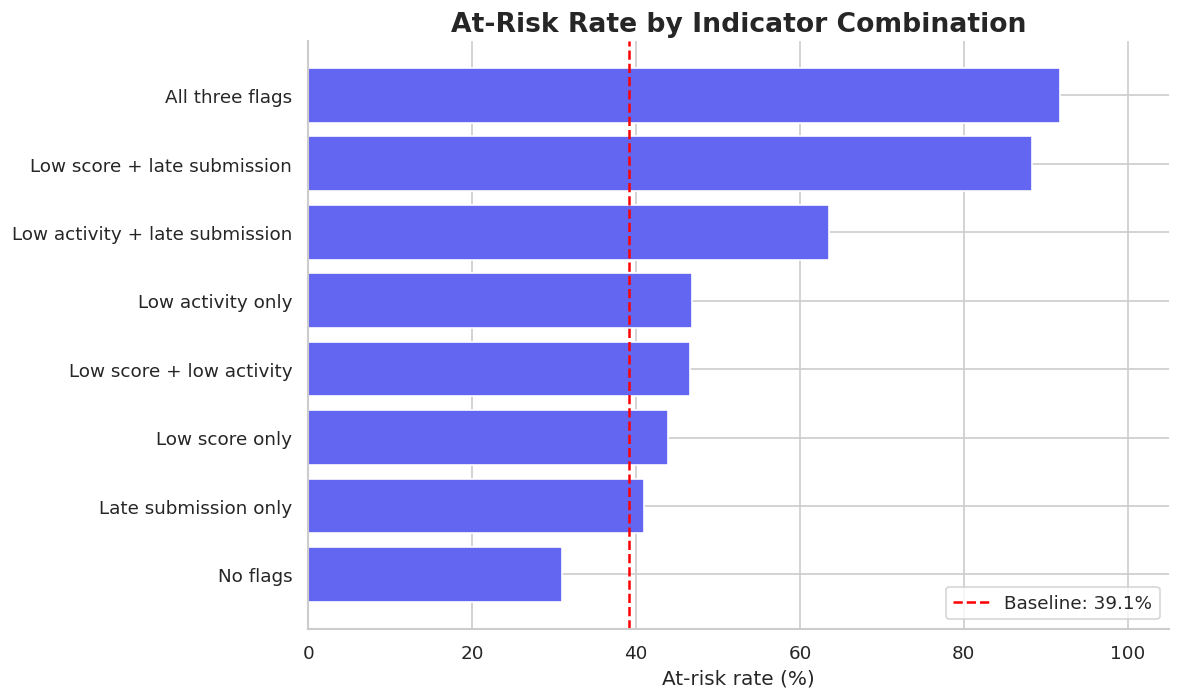

Results saved to: /kaggle/working/outputs/indicator_combinations


In [68]:
plot_data = ranked.sort_values("at_risk_rate")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data.index,
    plot_data["at_risk_rate"] * 100,
    color="#6366F1"
)

ax.axvline(
    baseline_rate * 100,
    color="red",
    linestyle="--",
    label=f"Baseline: {baseline_rate:.1%}"
)

ax.set_xlabel("At-risk rate (%)")
ax.set_ylabel("")
ax.set_title("At-Risk Rate by Indicator Combination")
ax.set_xlim(0, 105)
ax.legend()

plt.tight_layout()

fig.savefig(
    RESULTS_DIR / "segment_at_risk_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

segment_table.reset_index().to_csv(
    RESULTS_DIR / "segment_table.csv",
    index=False
)

coverage.to_csv(
    RESULTS_DIR / "analysis_coverage.csv",
    index=False
)

chi_results.to_csv(
    RESULTS_DIR / "chi_square_results.csv",
    index=False
)

(RESULTS_DIR / "findings.txt").write_text(
    findings,
    encoding="utf-8"
)

print("Results saved to:", RESULTS_DIR.resolve())

# Semester-over-Semester Retention Funnel Analysis

Compare module progression across presentations:
2013B, 2013J, 2014B, and 2014J.

Stages:
1. Registered: all student-module enrolments.
2. Completed module: final result is Pass, Distinction, or Fail.
3. Passed module: final result is Pass or Distinction.

OULAD records single-module progression. Therefore, module completion
and passing represent the endpoint; they do not mean graduation.

Presentation comparisons describe different enrolment groups,
not necessarily the same students progressing between semesters.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

KEY = ["code_module", "code_presentation", "id_student"]
PRESENTATIONS = ["2013B", "2013J", "2014B", "2014J"]
FUNNEL_DIR = Path("outputs/retention_funnel")
FUNNEL_DIR.mkdir(parents=True, exist_ok=True)

retention = merged.loc[
    merged["code_presentation"].isin(PRESENTATIONS),
    KEY + ["final_result"]
].copy()
assert not retention.duplicated(KEY).any()
expected_results = ["Pass", "Distinction", "Fail", "Withdrawn"]
assert retention["final_result"].isin(expected_results).all()
print("Student-course enrolments:", len(retention))
print("Module-presentation combinations:", retention[["code_module", "code_presentation"]].drop_duplicates().shape[0])


Step 1: Create the completion and pass indicators

In [70]:
retention["completed"] = retention["final_result"].isin(
    ["Pass", "Distinction", "Fail"]
).astype(int)

retention["passed"] = retention["final_result"].isin(
    ["Pass", "Distinction"]
).astype(int)

Explanation:
- A student with Fail completed the module but did not pass.
- A student with Withdrawn did not reach the completion stage under this definition.
- 
Step 2: Count students at each stage

In [71]:
funnel_summary = (
    retention.groupby(
        ["code_module", "code_presentation"],
        observed=True
    )
    .agg(
        registered=("id_student", "size"),
        completed=("completed", "sum"),
        passed=("passed", "sum")
    )
    .reset_index()
)

# Keep presentations in chronological order
presentation_order = {
    name: position
    for position, name in enumerate(PRESENTATIONS)
}

funnel_summary["_order"] = (
    funnel_summary["code_presentation"].map(presentation_order)
)

funnel_summary = (
    funnel_summary
    .sort_values(["code_module", "_order"])
    .drop(columns="_order")
    .reset_index(drop=True)
)

# Verify that stage counts decrease or remain equal
assert (
    (funnel_summary["registered"] >= funnel_summary["completed"])
    & (funnel_summary["completed"] >= funnel_summary["passed"])
).all()

display(funnel_summary)

,code_module,code_presentation,registered,completed,passed
0,AAA,2013J,383,323,278
1,AAA,2014J,365,299,253
2,BBB,2013B,1767,1262,803
3,BBB,2013J,2237,1593,1072
4,BBB,2014B,1613,1123,727
5,BBB,2014J,2292,1543,1152
6,CCC,2014B,1936,1038,663
7,CCC,2014J,2498,1421,1015
8,DDD,2013B,1303,871,510
9,DDD,2013J,1938,1257,829


Explanation: Each row now contains the funnel counts for one module and presentation. Unavailable module–presentation combinations are omitted, rather than shown as zero enrolments.

Step 3: Calculate drop-offs

In [72]:
# Registration → completion
funnel_summary["registration_to_completion_drop"] = (
    funnel_summary["registered"] - funnel_summary["completed"]
)

funnel_summary["registration_to_completion_drop_pct"] = (
    funnel_summary["registration_to_completion_drop"]
    / funnel_summary["registered"]
    * 100
)

# Completion → pass
funnel_summary["completion_to_pass_drop"] = (
    funnel_summary["completed"] - funnel_summary["passed"]
)

funnel_summary["completion_to_pass_drop_pct"] = (
    funnel_summary["completion_to_pass_drop"]
    / funnel_summary["completed"].replace(0, np.nan)
    * 100
)

# Overall rates, using registered enrolments as the denominator
funnel_summary["completion_rate_pct"] = (
    funnel_summary["completed"]
    / funnel_summary["registered"]
    * 100
)

funnel_summary["pass_rate_pct"] = (
    funnel_summary["passed"]
    / funnel_summary["registered"]
    * 100
)

display(funnel_summary.round(2))

,code_module,code_presentation,registered,completed,passed,registration_to_completion_drop,registration_to_completion_drop_pct,completion_to_pass_drop,completion_to_pass_drop_pct,completion_rate_pct,pass_rate_pct
0,AAA,2013J,383,323,278,60,15.67,45,13.93,84.33,72.58
1,AAA,2014J,365,299,253,66,18.08,46,15.38,81.92,69.32
2,BBB,2013B,1767,1262,803,505,28.58,459,36.37,71.42,45.44
3,BBB,2013J,2237,1593,1072,644,28.79,521,32.71,71.21,47.92
4,BBB,2014B,1613,1123,727,490,30.38,396,35.26,69.62,45.07
5,BBB,2014J,2292,1543,1152,749,32.68,391,25.34,67.32,50.26
6,CCC,2014B,1936,1038,663,898,46.38,375,36.13,53.62,34.25
7,CCC,2014J,2498,1421,1015,1077,43.11,406,28.57,56.89,40.63
8,DDD,2013B,1303,871,510,432,33.15,361,41.45,66.85,39.14
9,DDD,2013J,1938,1257,829,681,35.14,428,34.05,64.86,42.78


Explanation: Drop-off percentages use the previous stage as their denominator. Overall completion and pass rates use registered enrolments.

Step 4: Find the largest drop-off in each funnel

In [73]:
completion_drops = funnel_summary[
    [
        "code_module",
        "code_presentation",
        "registration_to_completion_drop",
        "registration_to_completion_drop_pct"
    ]
].rename(columns={
    "registration_to_completion_drop": "drop_count",
    "registration_to_completion_drop_pct": "drop_pct"
})

completion_drops["transition"] = "Registration → completion"

pass_drops = funnel_summary[
    [
        "code_module",
        "code_presentation",
        "completion_to_pass_drop",
        "completion_to_pass_drop_pct"
    ]
].rename(columns={
    "completion_to_pass_drop": "drop_count",
    "completion_to_pass_drop_pct": "drop_pct"
})

pass_drops["transition"] = "Completion → pass"

dropoff_table = pd.concat(
    [completion_drops, pass_drops],
    ignore_index=True
)

# Retain ties when both transitions have the same largest loss
largest_in_funnel = dropoff_table.groupby(
    ["code_module", "code_presentation"]
)["drop_count"].transform("max")

largest_dropoffs = dropoff_table.loc[
    dropoff_table["drop_count"].eq(largest_in_funnel)
].copy()

display(
    largest_dropoffs.sort_values(
        "drop_count",
        ascending=False
    ).round(2)
)

,code_module,code_presentation,drop_count,drop_pct,transition
7,CCC,2014J,1077,43.11,Registration → completion
6,CCC,2014B,898,46.38,Registration → completion
18,FFF,2014J,855,36.15,Registration → completion
5,BBB,2014J,749,32.68,Registration → completion
9,DDD,2013J,681,35.14,Registration → completion
16,FFF,2013J,675,29.57,Registration → completion
11,DDD,2014J,647,35.88,Registration → completion
3,BBB,2013J,644,28.79,Registration → completion
2,BBB,2013B,505,28.58,Registration → completion
4,BBB,2014B,490,30.38,Registration → completion


Explanation: This identifies the largest loss by number of enrolments in each funnel. We will also report the largest percentage loss separately.

Step 5: Save a funnel figure for every module and presentation
The widest bar represents registration. Later bars show how many enrolments reached each stage.

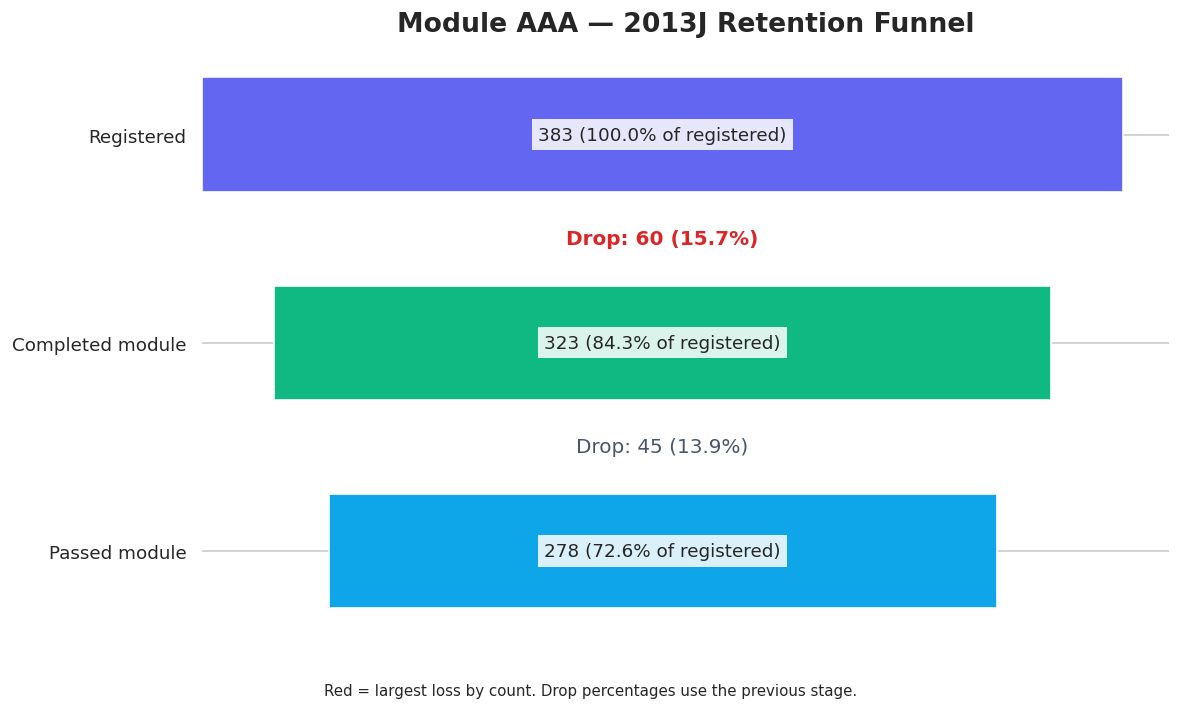

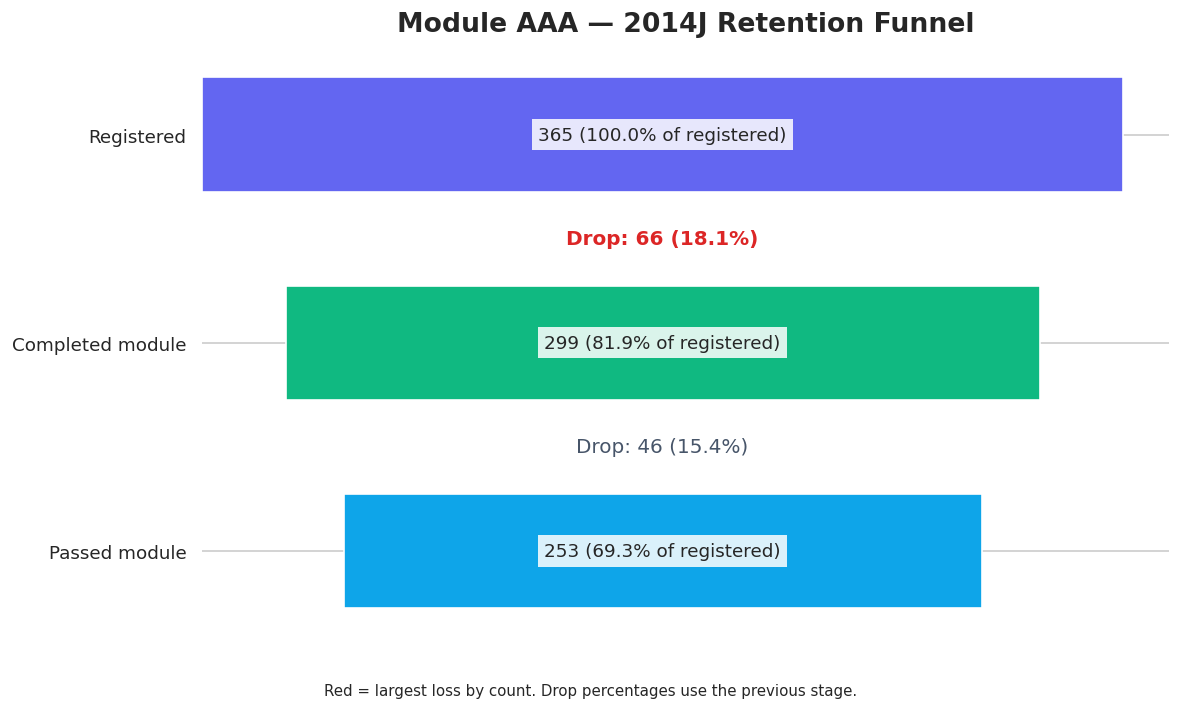

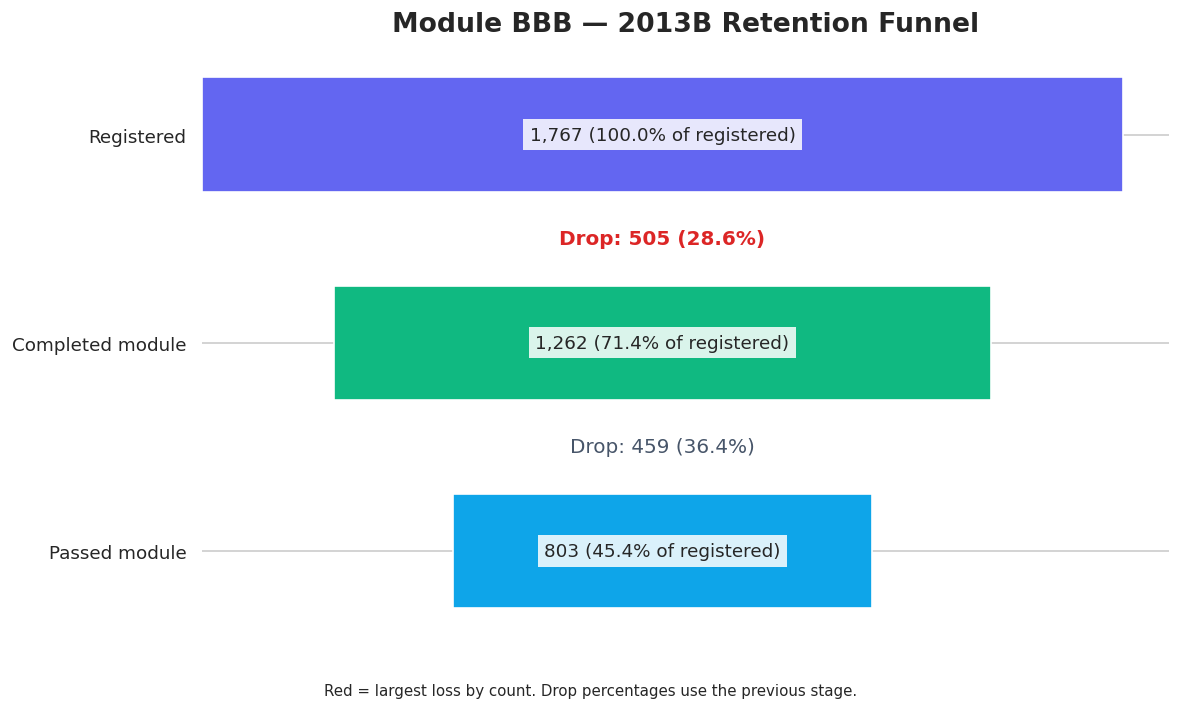

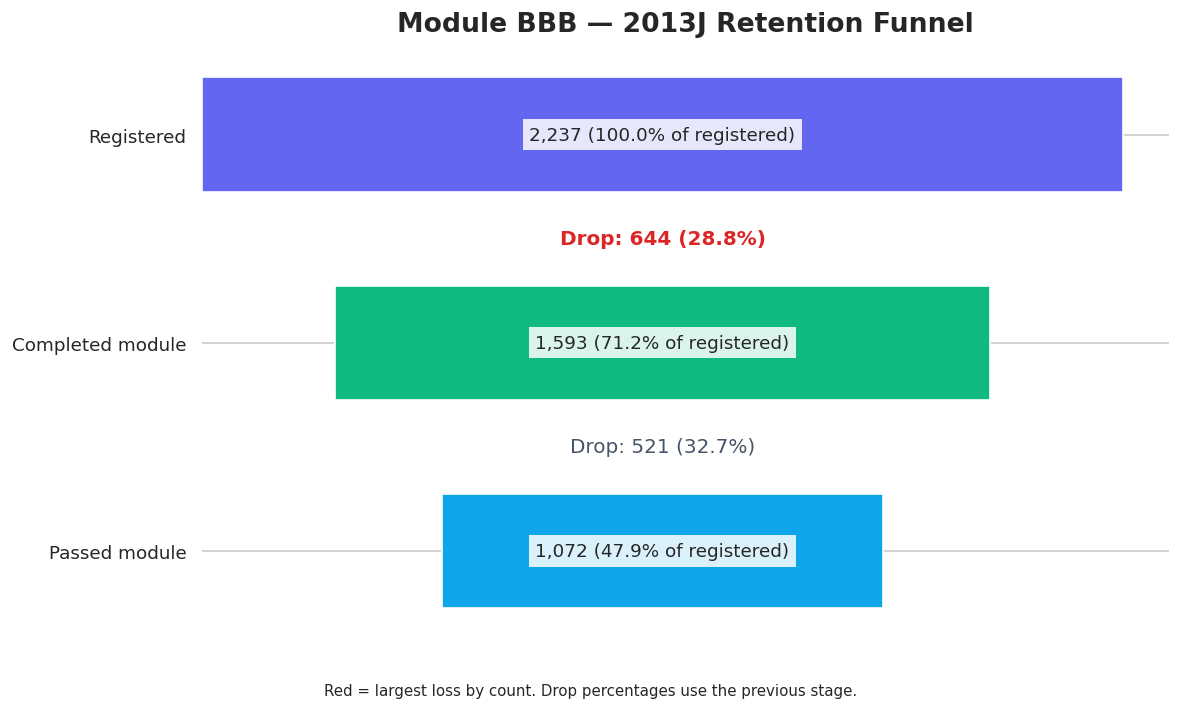

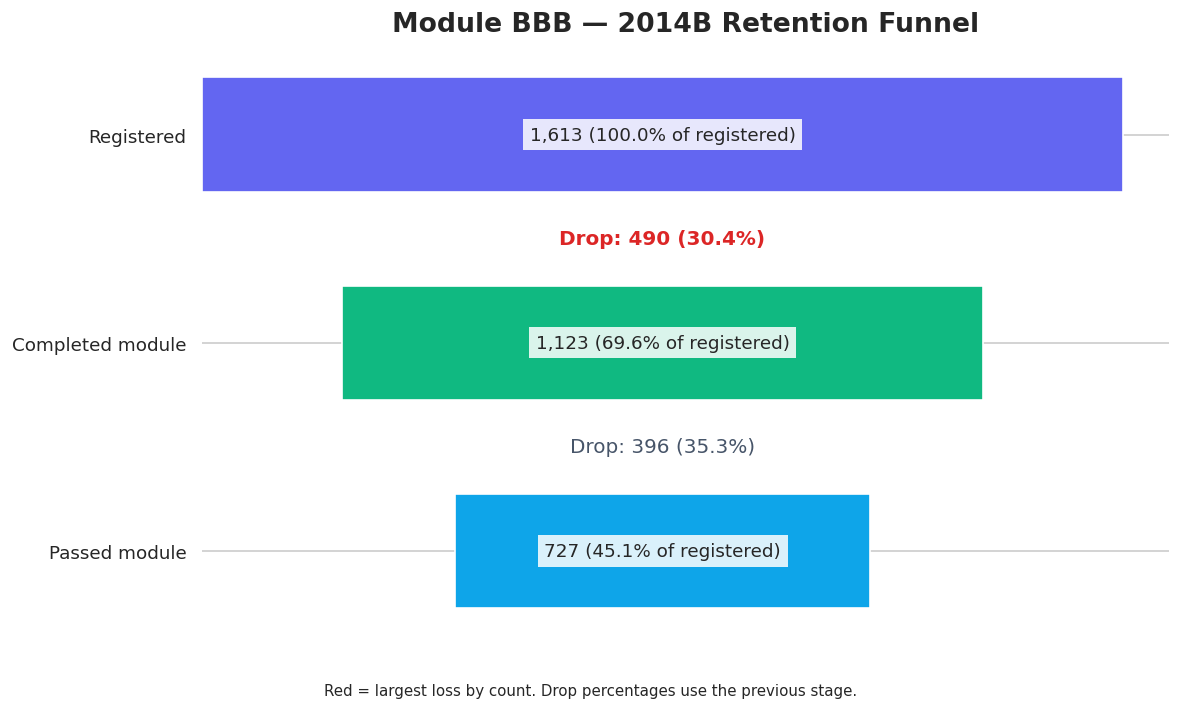

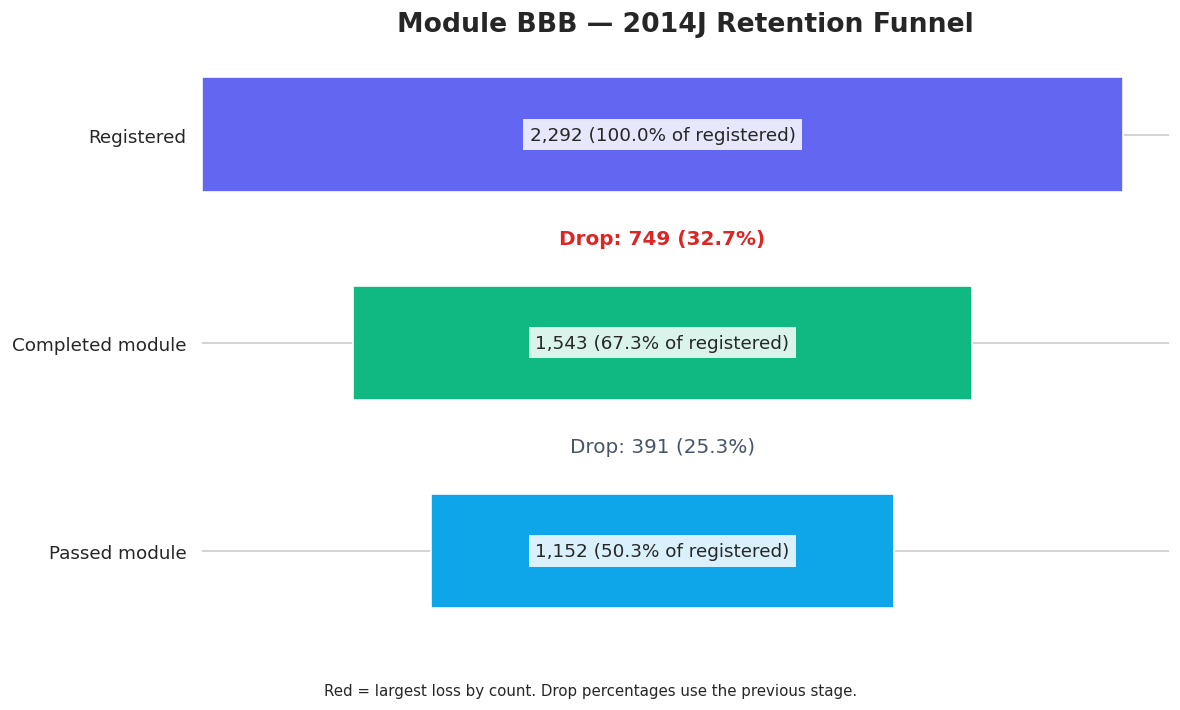

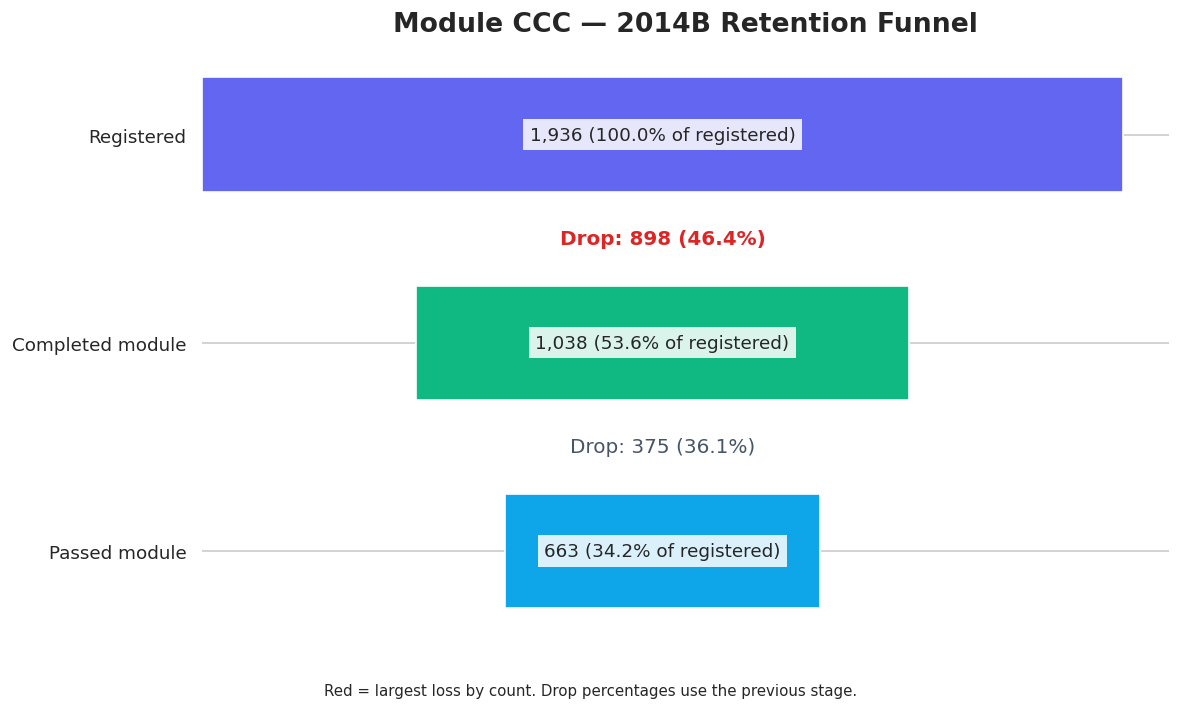

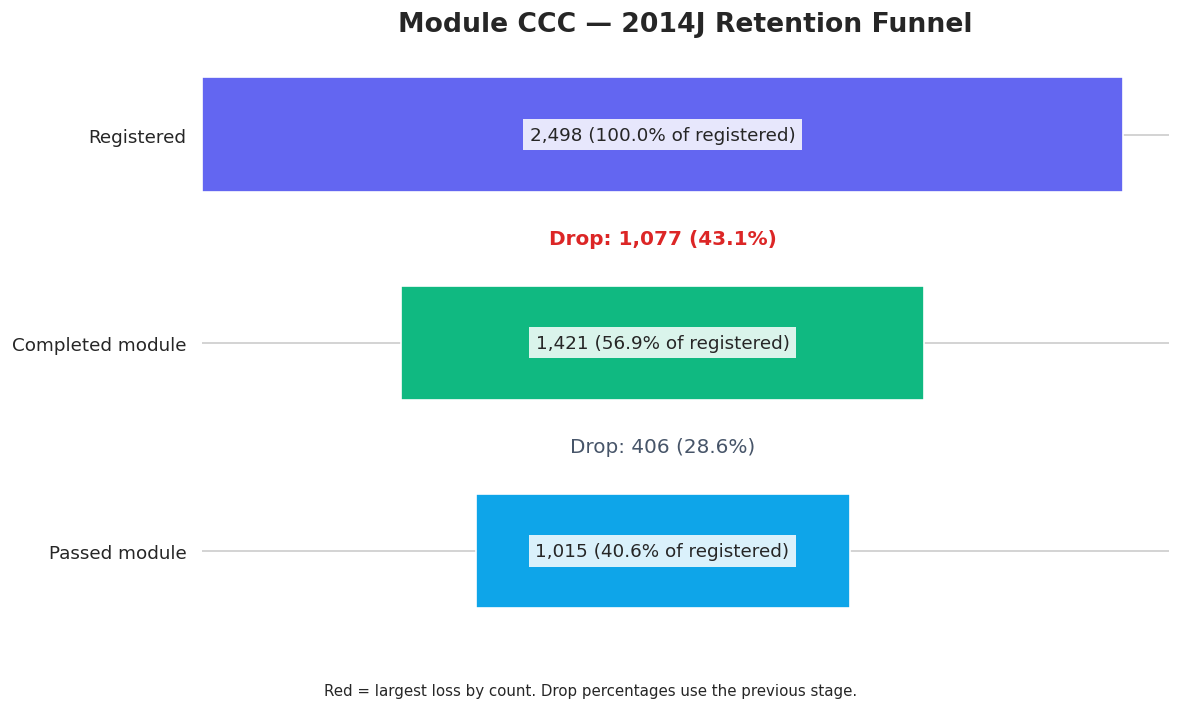

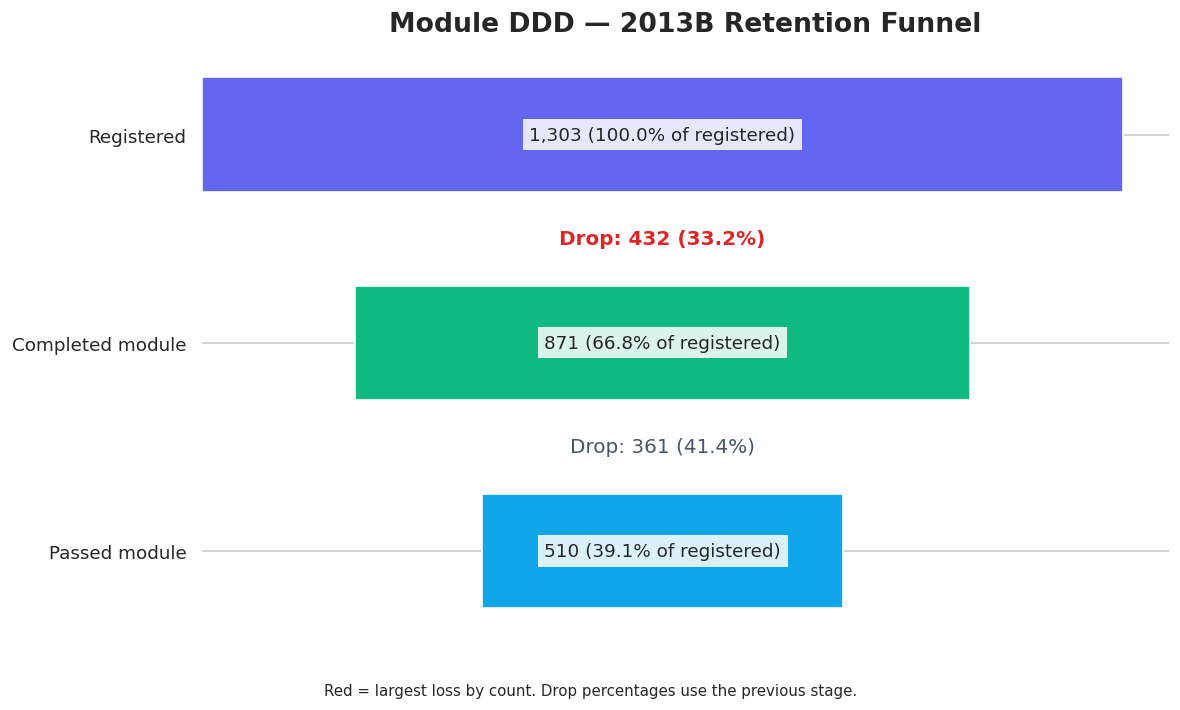

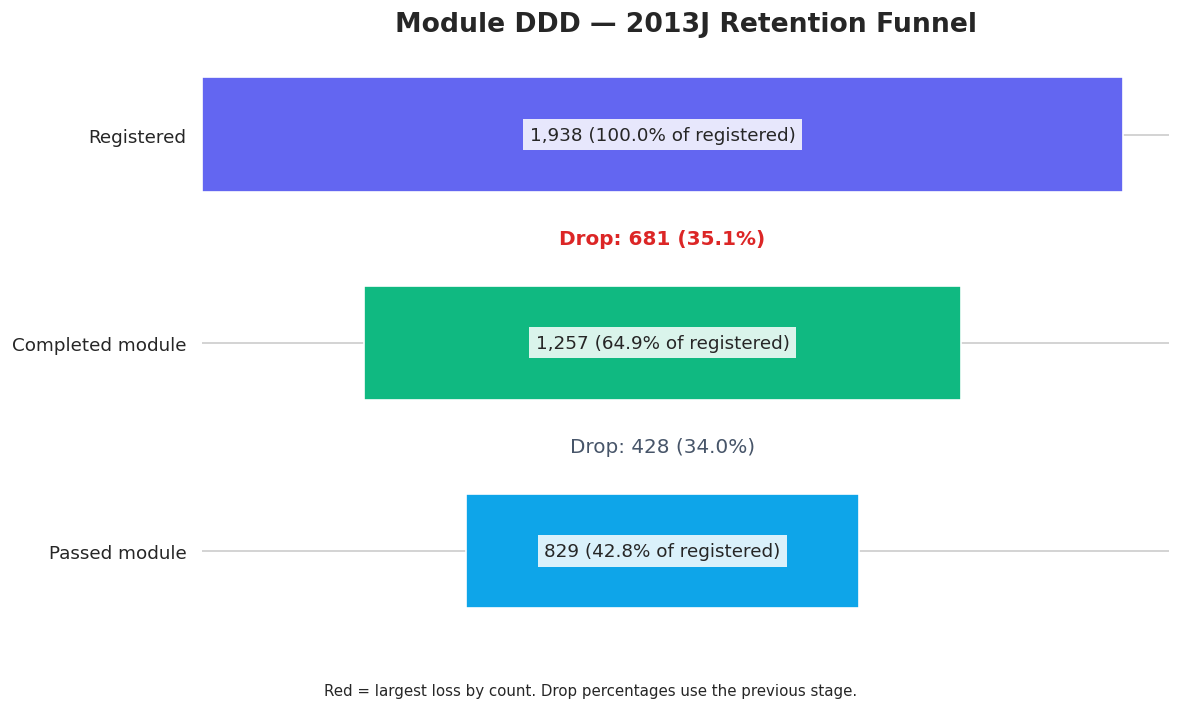

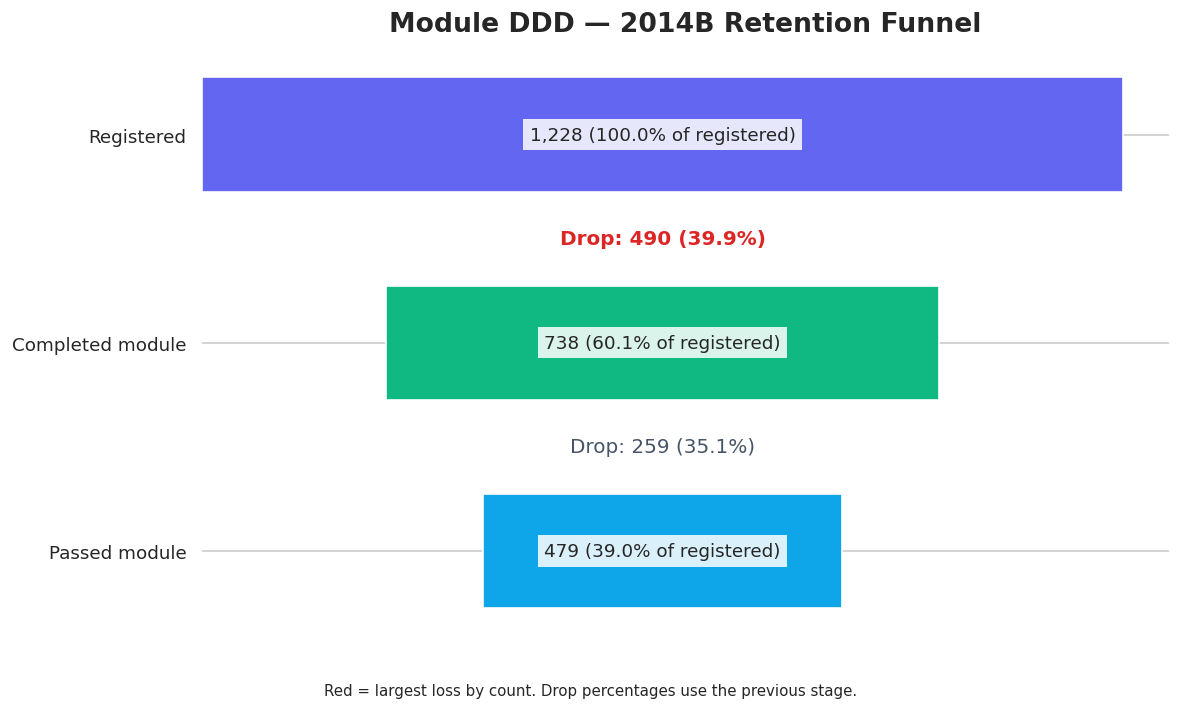

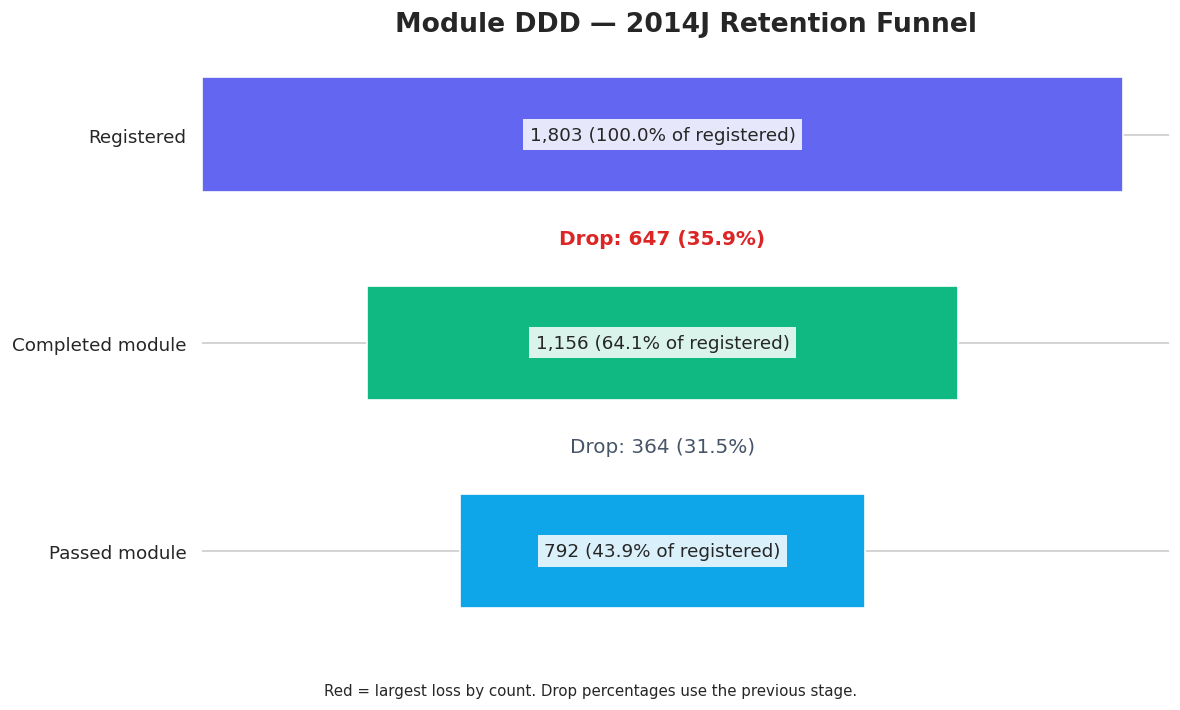

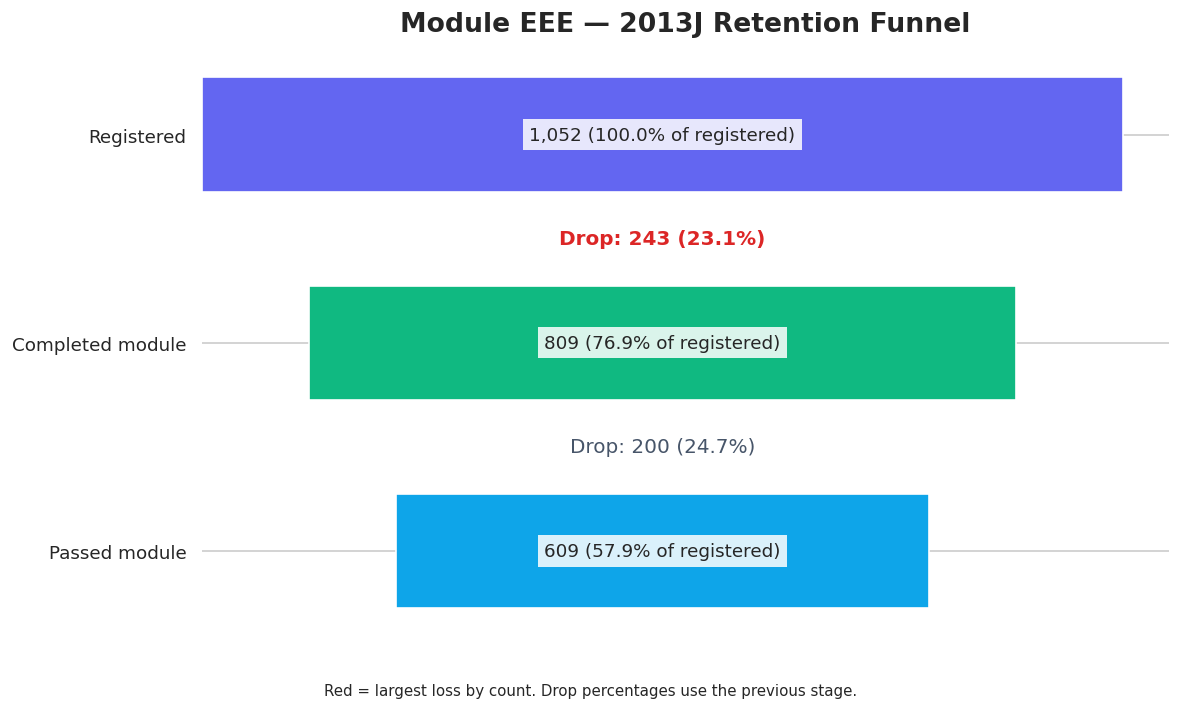

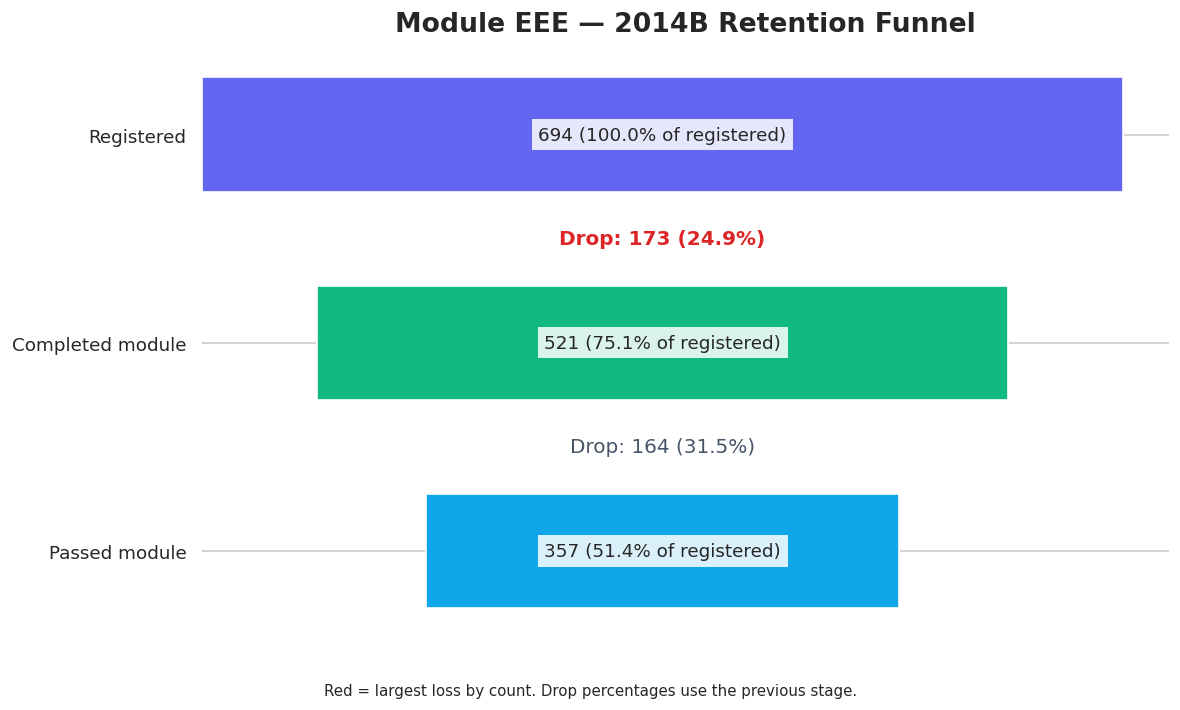

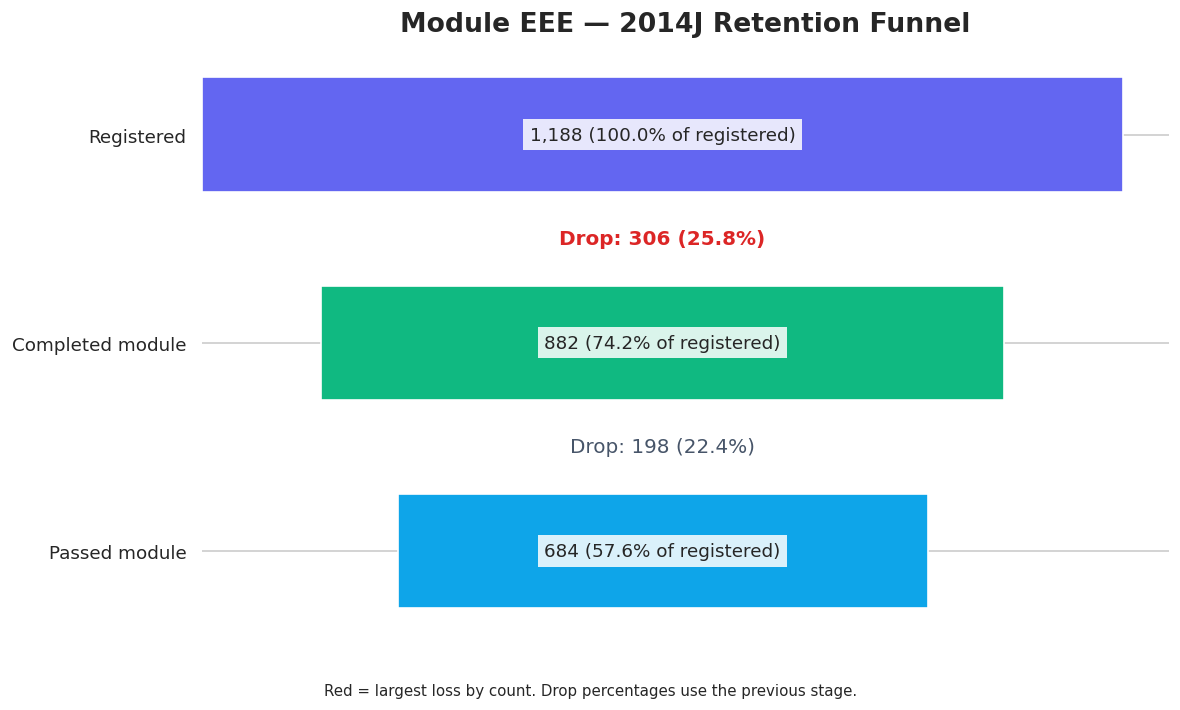

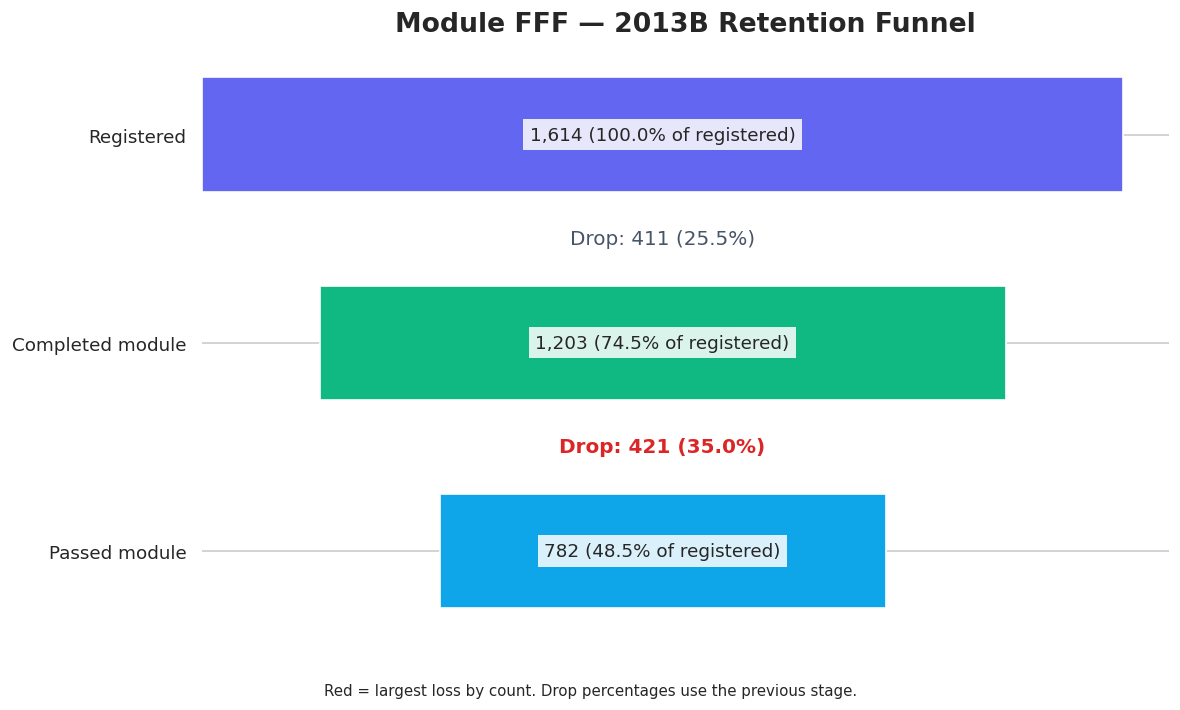

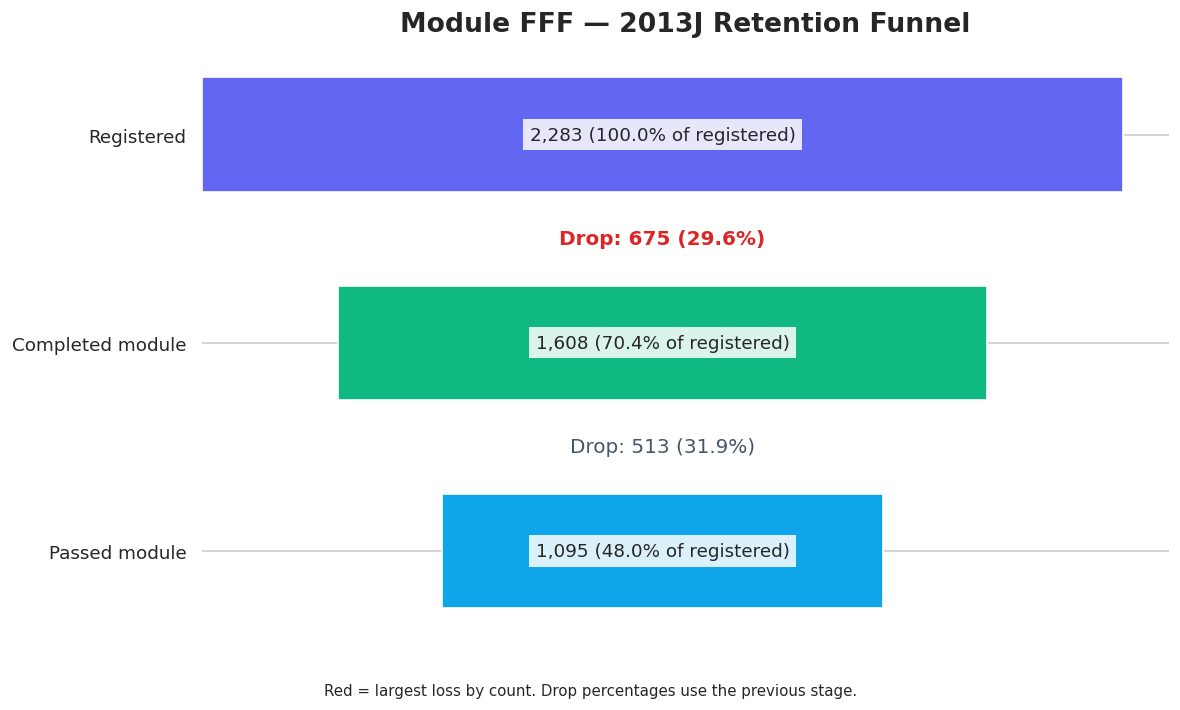

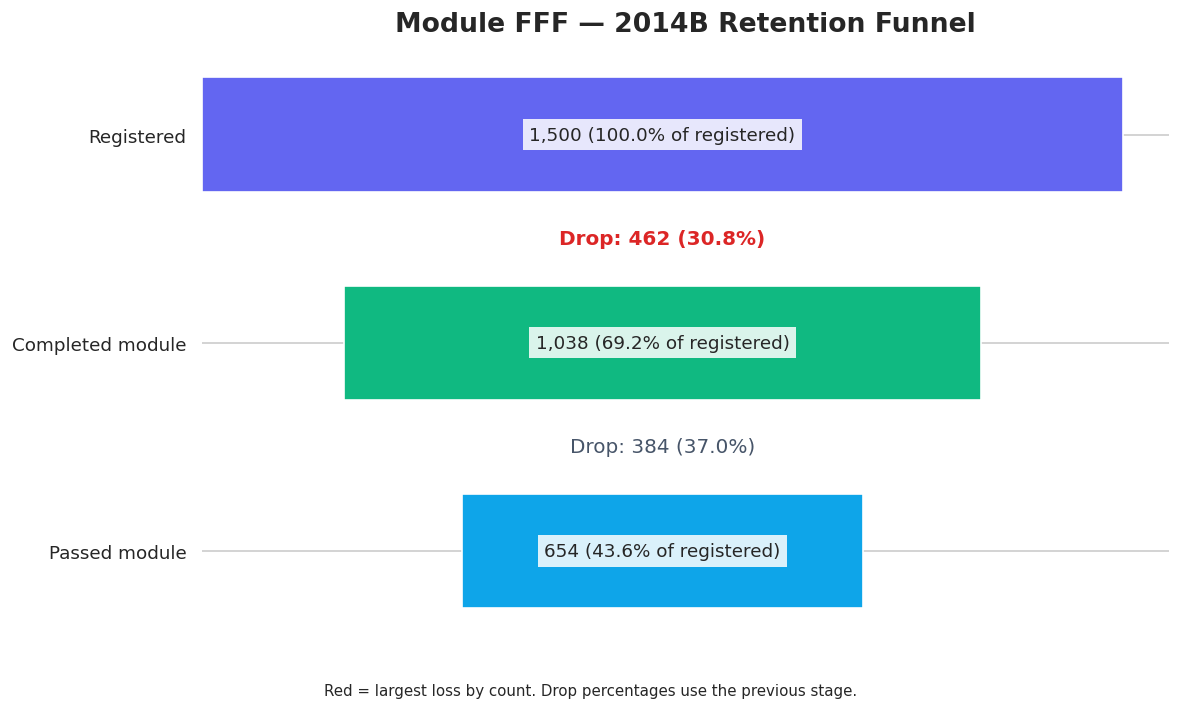

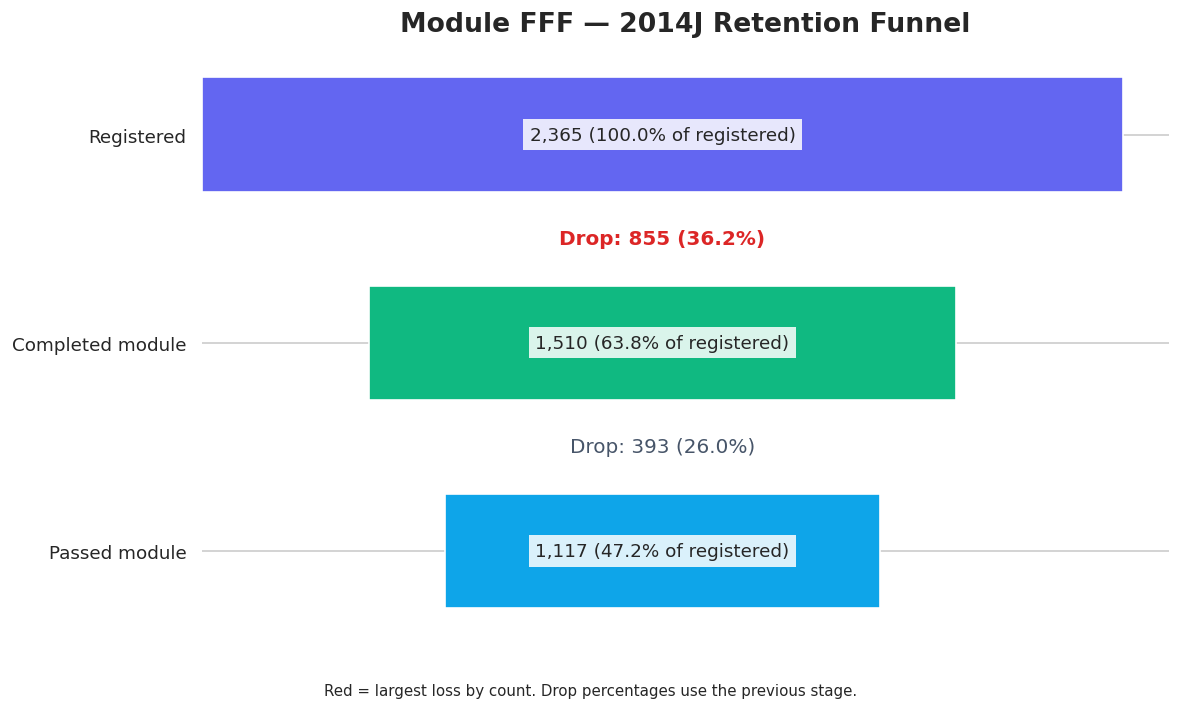

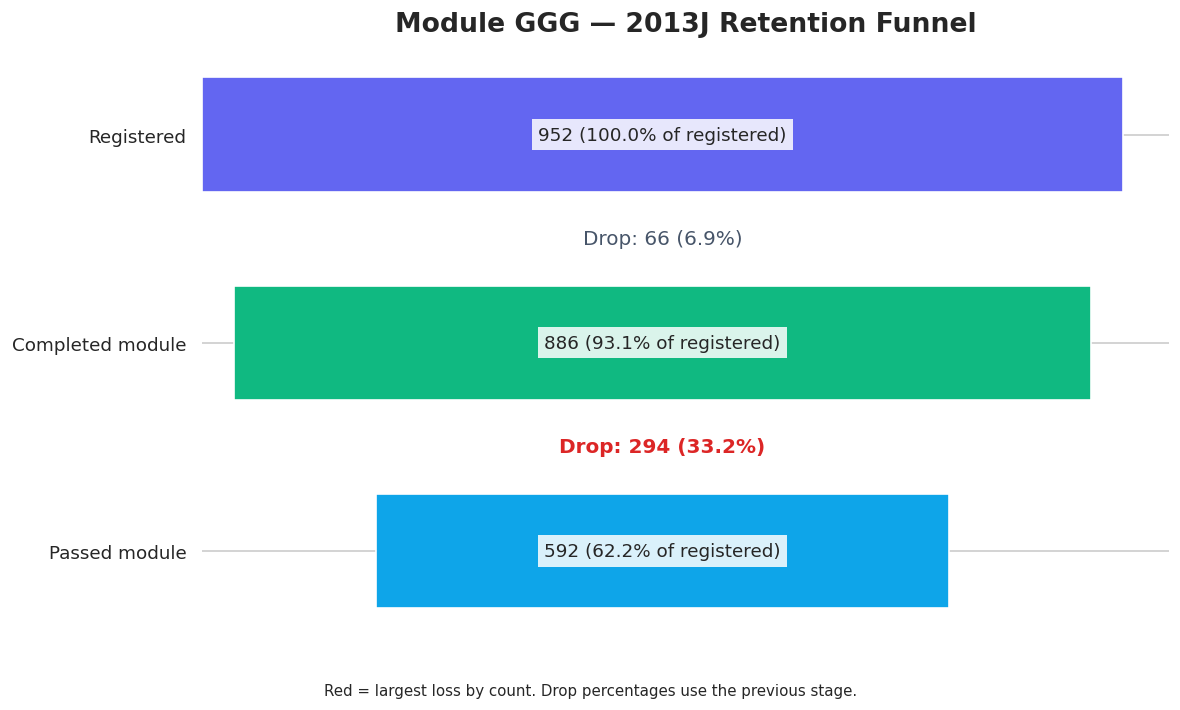

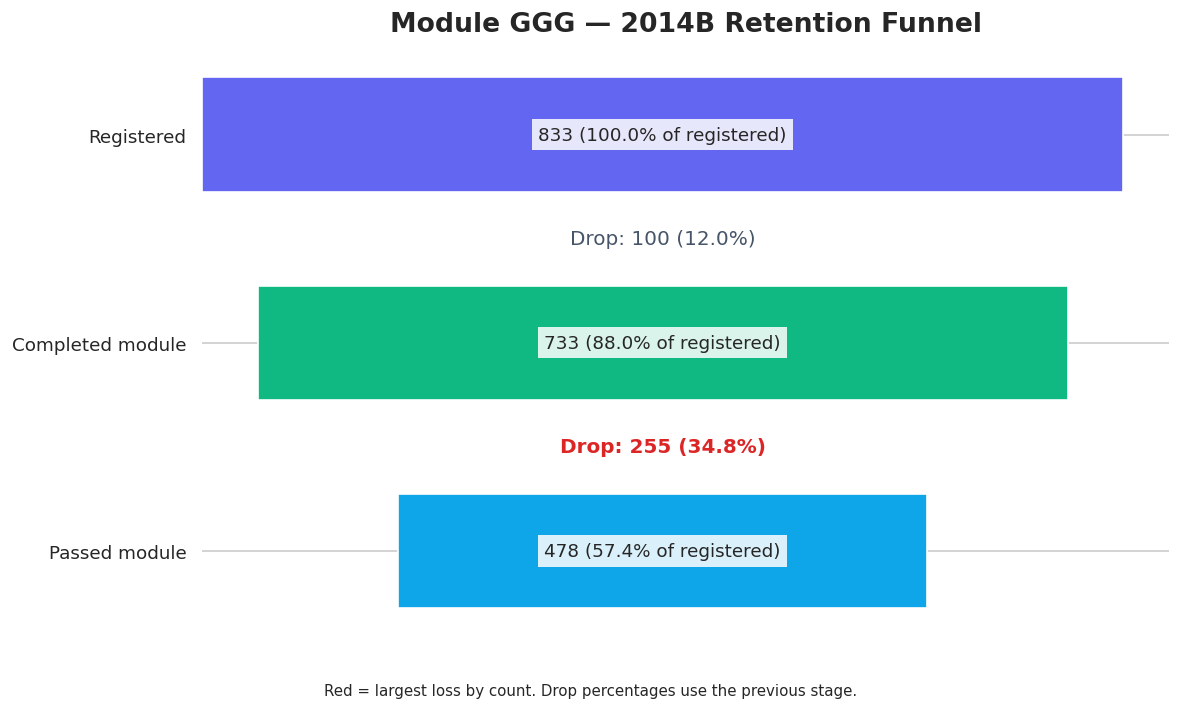

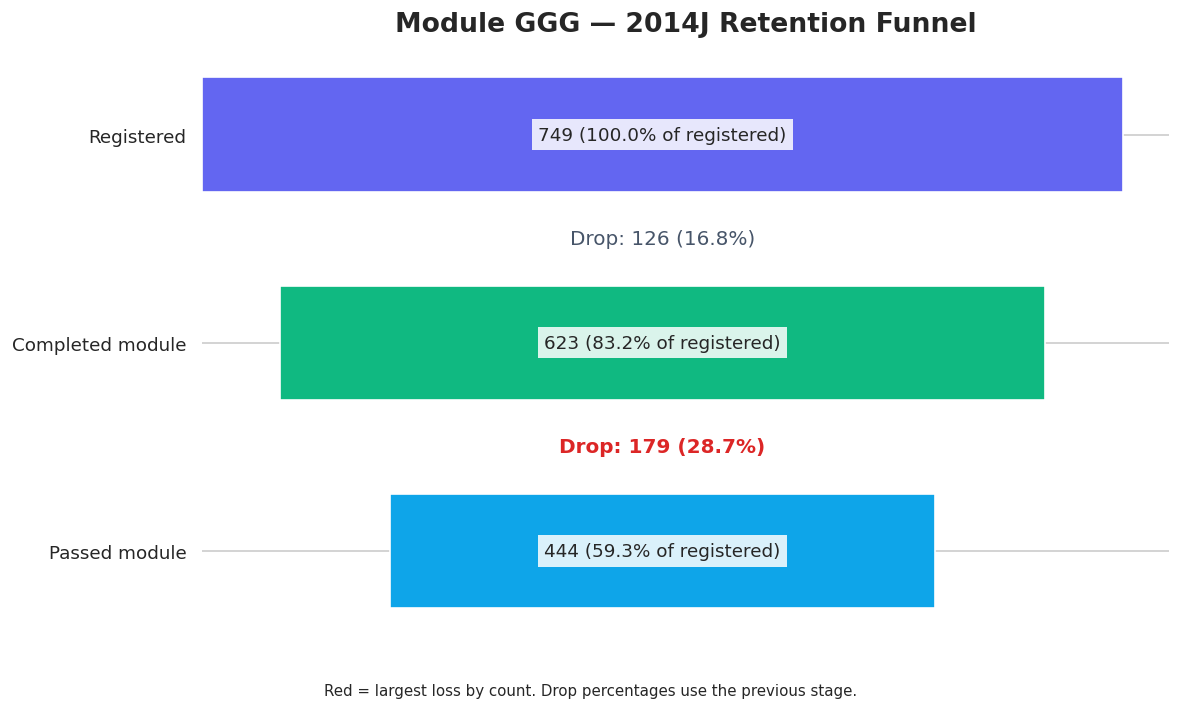

In [74]:
stage_labels = [
    "Registered",
    "Completed module",
    "Passed module"
]

stage_colors = ["#6366F1", "#10B981", "#0EA5E9"]

for _, row in funnel_summary.iterrows():

    counts = np.array([
        row["registered"],
        row["completed"],
        row["passed"]
    ], dtype=int)

    registered = counts[0]

    # Centre each bar to create a funnel
    left_positions = (registered - counts) / 2

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.barh(
        [0, 1, 2],
        counts,
        left=left_positions,
        height=0.55,
        color=stage_colors
    )

    for position, count in enumerate(counts):
        percentage = count / registered * 100

        ax.text(
            registered / 2,
            position,
            f"{count:,} ({percentage:.1f}% of registered)",
            ha="center",
            va="center",
            fontsize=11,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85
            )
        )

    first_loss = row["registration_to_completion_drop"]
    first_pct = row["registration_to_completion_drop_pct"]

    second_loss = row["completion_to_pass_drop"]
    second_pct = row["completion_to_pass_drop_pct"]

    first_label = (
        f"Drop: {first_loss:,.0f} ({first_pct:.1f}%)"
    )

    second_label = (
        f"Drop: {second_loss:,.0f} ({second_pct:.1f}%)"
        if pd.notna(second_pct)
        else "Drop: 0 (N/A: no completers)"
    )

    # Highlight the largest loss by count; highlight both if tied
    for position, label, loss in [
        (0.5, first_label, first_loss),
        (1.5, second_label, second_loss)
    ]:
        is_largest = loss == max(first_loss, second_loss)

        ax.text(
            registered / 2,
            position,
            label,
            ha="center",
            va="center",
            color="#DC2626" if is_largest else "#475569",
            fontweight="bold" if is_largest else "normal"
        )

    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(stage_labels)
    ax.set_ylim(2.45, -0.45)
    ax.set_xlim(0, registered * 1.05)

    ax.set_title(
        f"Module {row['code_module']} — "
        f"{row['code_presentation']} Retention Funnel"
    )

    ax.set_xticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.text(
        0.5,
        0.02,
        "Red = largest loss by count. "
        "Drop percentages use the previous stage.",
        ha="center",
        fontsize=9
    )

    plt.tight_layout(rect=[0, 0.06, 1, 1])

    filename = (
        f"funnel_{row['code_module']}_"
        f"{row['code_presentation']}.png"
    )

    fig.savefig(
        FUNNEL_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

Step 6: Compare presentations within each module
Use percentages because presentation sizes differ.

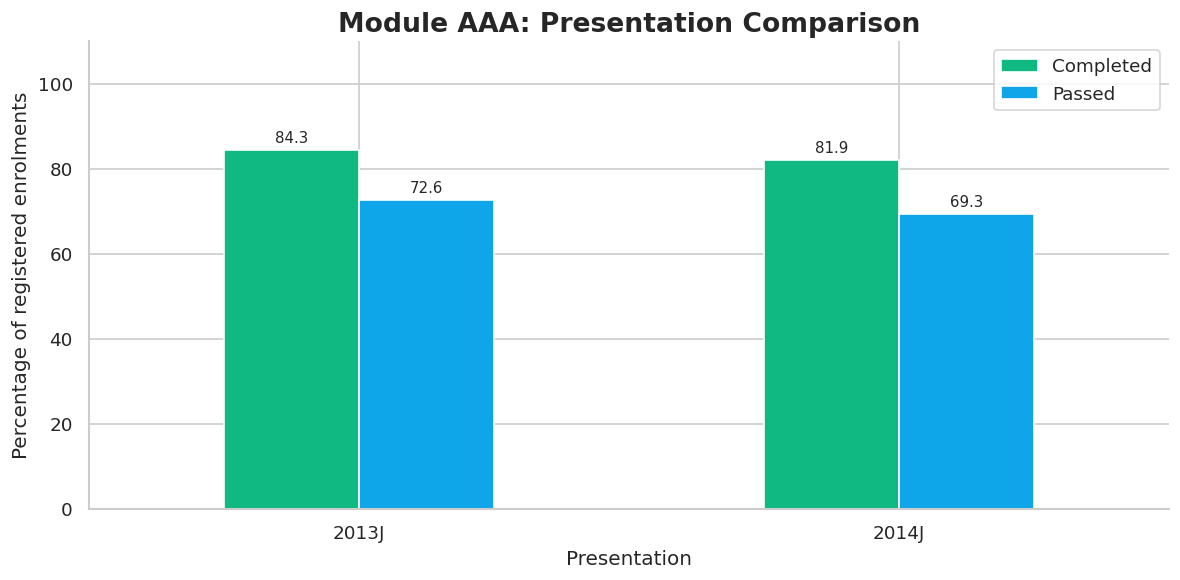

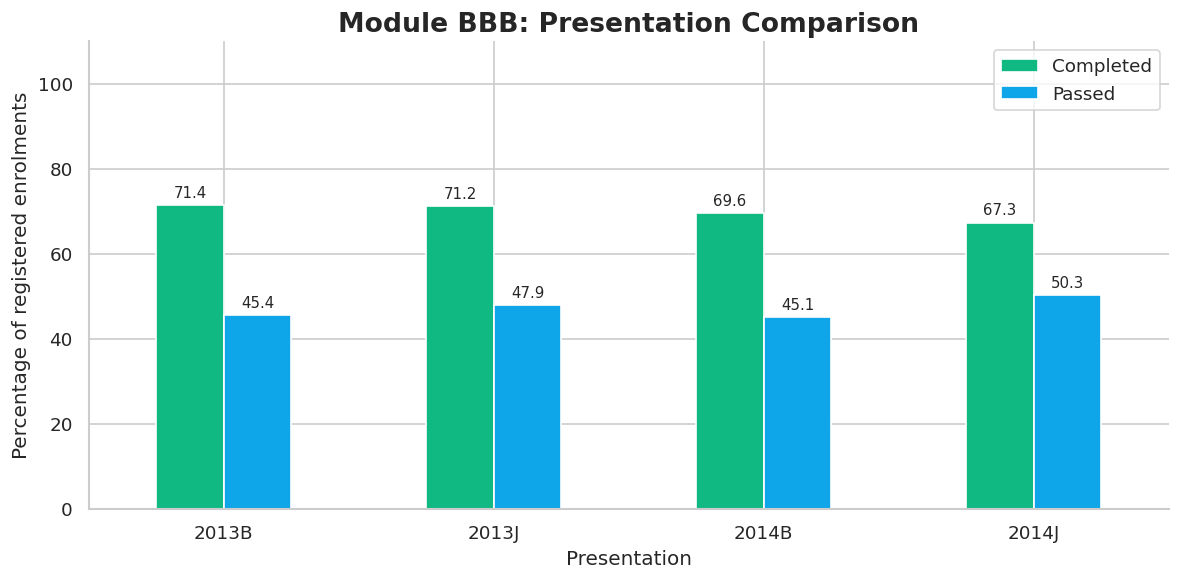

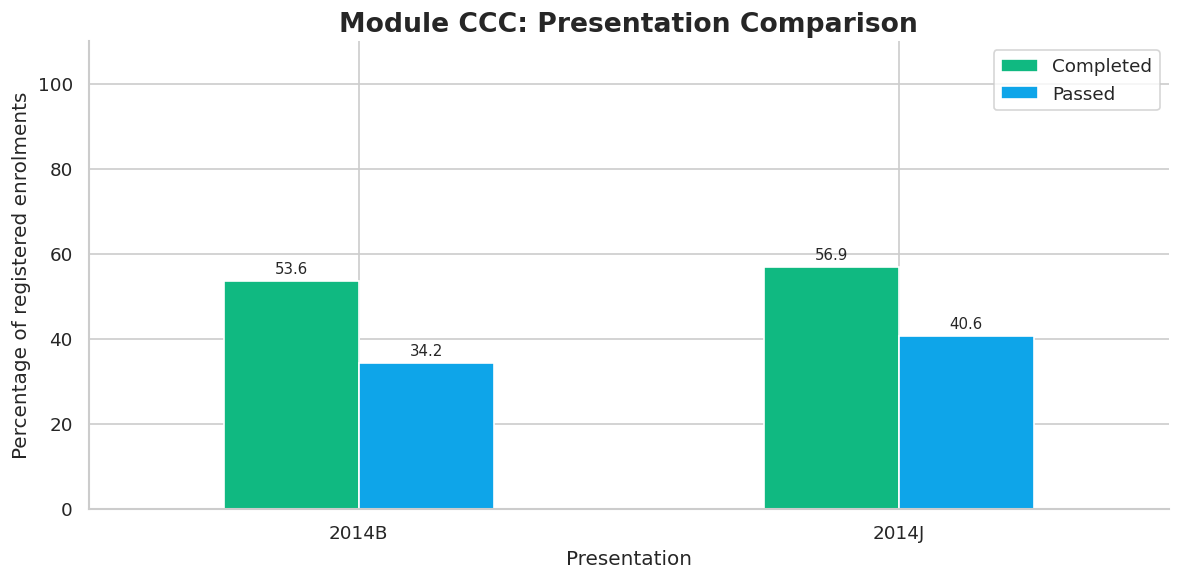

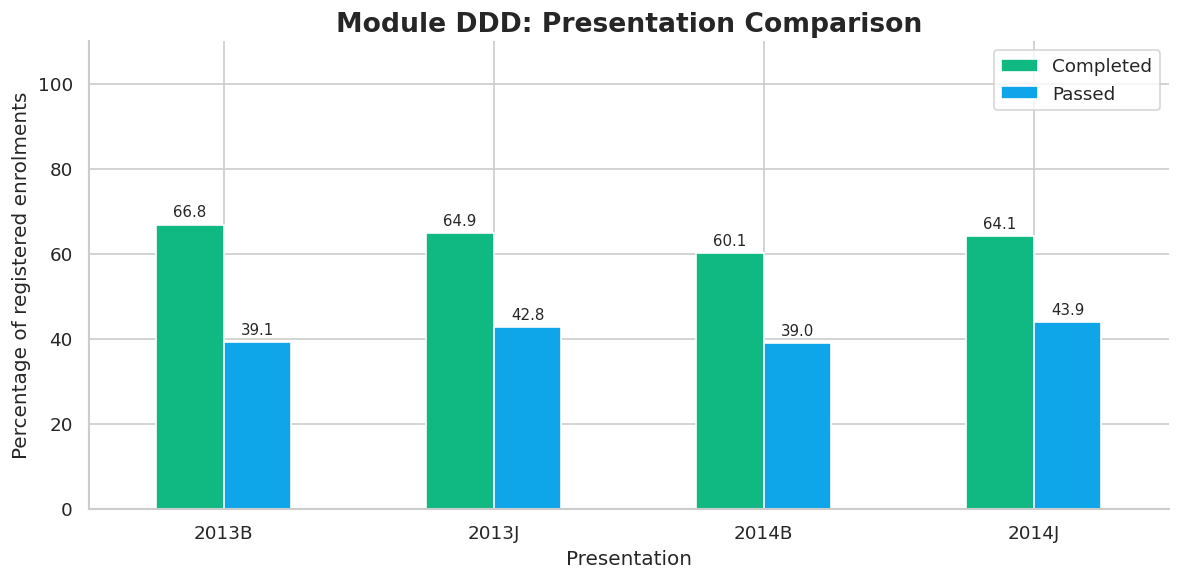

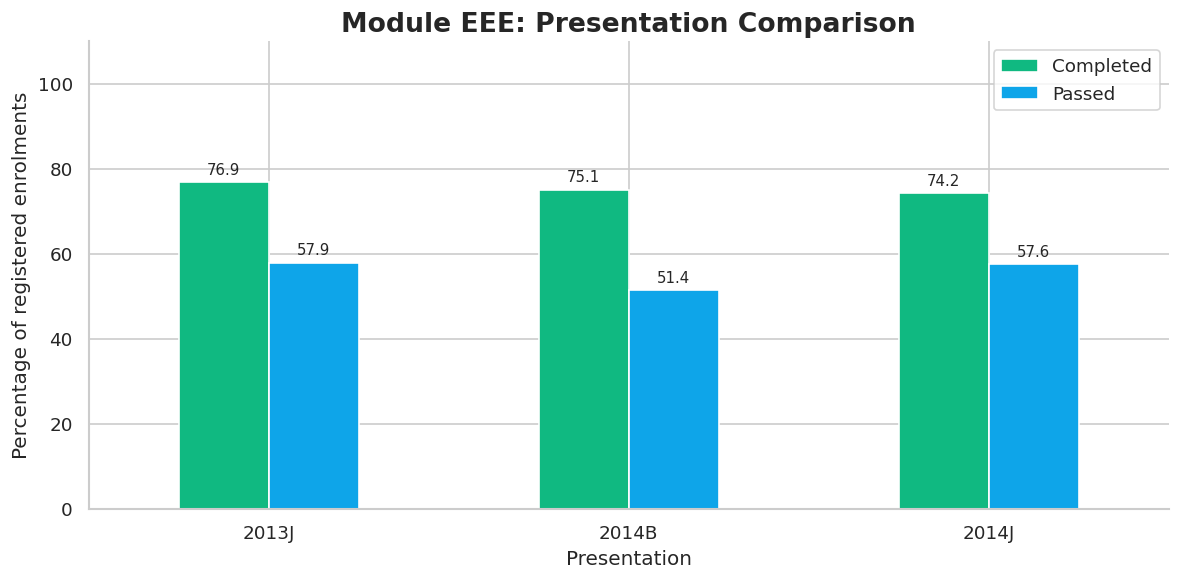

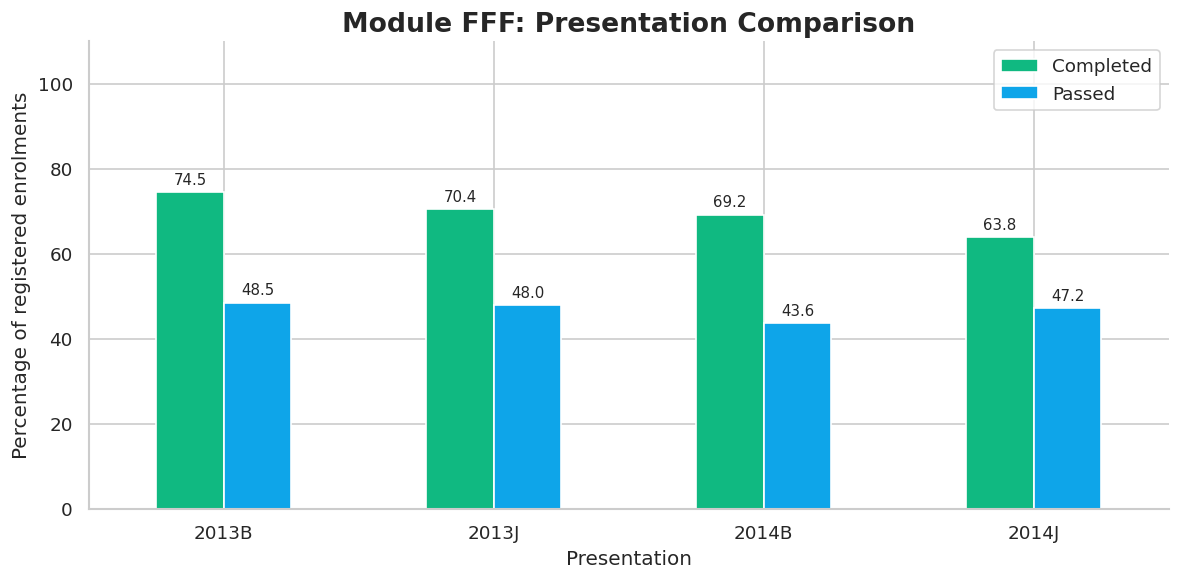

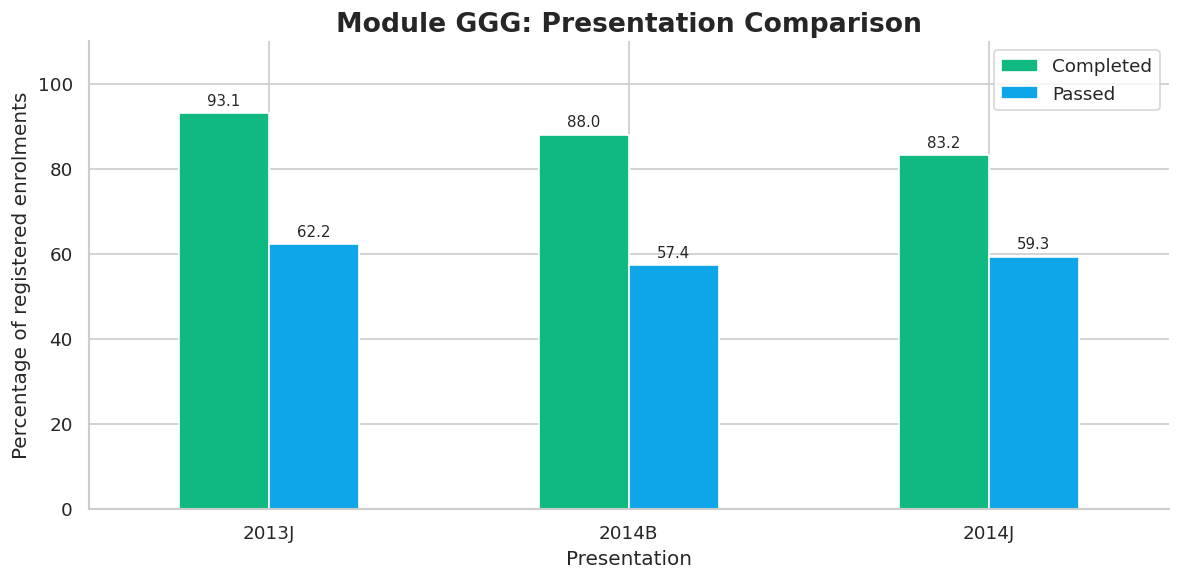

In [75]:
for module, module_data in funnel_summary.groupby("code_module"):

    comparison = (
        module_data.set_index("code_presentation")[
            ["completion_rate_pct", "pass_rate_pct"]
        ]
        .reindex(PRESENTATIONS)
        .dropna(how="all")
        .rename(columns={
            "completion_rate_pct": "Completed",
            "pass_rate_pct": "Passed"
        })
    )

    ax = comparison.plot(
        kind="bar",
        figsize=(10, 5),
        color=["#10B981", "#0EA5E9"],
        rot=0
    )

    ax.set_title(f"Module {module}: Presentation Comparison")
    ax.set_xlabel("Presentation")
    ax.set_ylabel("Percentage of registered enrolments")
    ax.set_ylim(0, 110)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f",
            padding=3,
            fontsize=9
        )

    plt.tight_layout()

    ax.figure.savefig(
        FUNNEL_DIR / f"presentation_comparison_{module}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(ax.figure)

In [76]:
largest_count = dropoff_table.loc[
    dropoff_table["drop_count"].eq(dropoff_table["drop_count"].max())
]

valid_percentages = dropoff_table.dropna(subset=["drop_pct"])

largest_percentage = valid_percentages.loc[
    valid_percentages["drop_pct"].eq(
        valid_percentages["drop_pct"].max()
    )
]

findings_lines = [
    "Semester-over-semester retention funnel analysis",
    "",
    "Largest drop-off by enrolment count:"
]

for _, row in largest_count.iterrows():
    findings_lines.append(
        f"- Module {row['code_module']}, "
        f"{row['code_presentation']}: "
        f"{row['transition']}, losing "
        f"{int(row['drop_count']):,} enrolments "
        f"({row['drop_pct']:.1f}% of the previous stage)."
    )

findings_lines.extend([
    "",
    "Largest drop-off by percentage:"
])

for _, row in largest_percentage.iterrows():
    findings_lines.append(
        f"- Module {row['code_module']}, "
        f"{row['code_presentation']}: "
        f"{row['transition']}, losing "
        f"{row['drop_pct']:.1f}% "
        f"({int(row['drop_count']):,} enrolments)."
    )

findings_lines.extend([
    "",
    "Interpretation:",
    "- Registration-to-completion loss represents Withdrawn outcomes.",
    "- Completion-to-pass loss represents Fail outcomes.",
    "- Completion is defined from final_result, not a separate "
    "completion-date record.",
    "- Comparisons describe different presentation populations; "
    "they do not establish why rates changed.",
    "- OULAD covers module progression, not graduation.",
    "- Missing module-presentation combinations are not zero enrolments."
])

retention_findings = "\n".join(findings_lines)

print(retention_findings)

funnel_summary.to_csv(
    FUNNEL_DIR / "retention_funnel_summary.csv",
    index=False
)

dropoff_table.to_csv(
    FUNNEL_DIR / "all_stage_dropoffs.csv",
    index=False
)

largest_dropoffs.to_csv(
    FUNNEL_DIR / "largest_dropoffs_by_funnel.csv",
    index=False
)

(FUNNEL_DIR / "retention_findings.txt").write_text(
    retention_findings,
    encoding="utf-8"
)

print("\nOutputs saved to:", FUNNEL_DIR.resolve())

Semester-over-semester retention funnel analysis

Largest drop-off by enrolment count:
- Module CCC, 2014J: Registration → completion, losing 1,077 enrolments (43.1% of the previous stage).

Largest drop-off by percentage:
- Module CCC, 2014B: Registration → completion, losing 46.4% (898 enrolments).

Interpretation:
- Registration-to-completion loss represents Withdrawn outcomes.
- Completion-to-pass loss represents Fail outcomes.
- Completion is defined from final_result, not a separate completion-date record.
- Comparisons describe different presentation populations; they do not establish why rates changed.
- OULAD covers module progression, not graduation.
- Missing module-presentation combinations are not zero enrolments.

Outputs saved to: /kaggle/working/outputs/retention_funnel
